# Proyecto Integrador – Fase 1: Planteamiento del Problema, Descripción y EDA

**Dataset:** *Hotel Booking Demand* (Kaggle, `jessemostipak/hotel-booking-demand`)

| | |
|---|---|
| **Asignatura** | Ciencia de Datos — Maestría en Inteligencia Artificial, Semestre II |
| **Institución** | Universidad de La Salle |
| **Integrantes** | Miguel Angel Ricardo · Jose Alexander Barahona Calderon |
| **Docente** | Fabián Camilo Castro Riveros |
| **Entregable** | Actividades 1 y 2 — Fase 1 |
| **Fecha de entrega** | 01 de noviembre de 2026 |

Este cuaderno es el **soporte reproducible** del informe *Informe_Fase1_EDA_Hotel_Booking_v2.docx*: cada cifra del informe se
calcula aquí. Las figuras se guardan en `figures/` con la numeración de **este cuaderno**; el informe presenta una selección con
numeración propia, según esta equivalencia:

| Informe | Cuaderno |
|---|---|
| Figura 1 – Faltantes | Figura 1 |
| Figura 2 – Diagramas de caja | Figura 2 |
| Figura 3 – Histogramas | Figura 3 |
| Figura 4 – Cancelación por hotel | Figura 4 |
| Figura 5 – Matriz de Pearson | Figura 12 |
| Figura 6 – Pearson vs. Spearman y V de Cramér | Figuras 14 y 17 |
| Figura 7 – Diagramas de dispersión | Figuras 15 y 16 |
| Figura 8 – Anticipación | Figura 7 |
| Figura 9 – Solicitudes especiales | Figura 11 |
| Figura 10 – Segmento y depósito | Figura 10 |

---

**Contenido**

1. Introducción y alcance
2. Preparación del entorno y carga de datos
3. Formulación del problema
4. Ficha técnica y diccionario de datos
5. Diagnóstico de calidad de los datos
6. Análisis univariado
7. Análisis bivariado y multivariado
8. Respuesta preliminar a las preguntas y conclusiones
9. Verificación final y reproducibilidad

**Anexo A.** Material didáctico de visualización (marco conceptual, Cuarteto de Anscombe, catálogo de gráficos básicos y "antes y después")

## 1. Introducción y alcance

### 1.1 Introducción
En la industria hotelera, una reserva cancelada es una habitación que se dejó de vender. El conjunto **Hotel Booking Demand**
contiene información real de reservas de dos hoteles en Portugal (un hotel de ciudad en Lisboa y un hotel resort en el Algarve)
con llegadas entre julio de 2015 y agosto de 2017. Este cuaderno formula el problema de negocio, describe el conjunto de datos con
detalle, diagnostica su calidad y desarrolla un **análisis exploratorio de datos (EDA)** univariado, bivariado y multivariado que
sirve de base para el modelado del proyecto integrador.

### 1.2 Alcance de la Fase 1
La **Fase 1** del proyecto integrador cubre el **planteamiento del problema, la descripción del conjunto de datos y el análisis
exploratorio**: formulación de preguntas y objetivos, ficha técnica y diccionario de variables, diagnóstico de calidad (faltantes,
duplicados, incoherencias y atípicos), estadística descriptiva, pruebas de asociación y visualización. Las decisiones de limpieza
que se aplican aquí son las mínimas para no distorsionar el análisis; el tratamiento completo de los datos y la construcción de
**modelos de clasificación, regresión y agrupamiento se desarrollan en las Fases 2 y 3**, a partir de los hallazgos y
recomendaciones de este cuaderno.

**Lineamientos técnicos**
* **Una sola tecnología: Python**, con pandas y NumPy (manipulación), Matplotlib (visualización) y SciPy (pruebas estadísticas).
* El cuaderno es **compatible con Google Colab** y se ejecuta de principio a fin sin configuraciones manuales.
* El dataset se descarga **directamente desde Kaggle** con la librería oficial `kagglehub`, **sin token** (es público), con un
  espejo público como respaldo.
* Todo muestreo usa la semilla fija `SEED = 42`.

### 1.3 Justificación de la elección del dataset

Se eligió el dataset **Hotel Booking Demand** ([Kaggle — jessemostipak/hotel-booking-demand](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand))
porque **cumple los requisitos del proyecto integrador (ver la sección 4.3)**. Sus ventajas concretas:

| Criterio | Por qué es relevante para el proyecto integrador |
|---|---|
| **Continuidad** | El análisis exploratorio de esta fase es la base de las Fases 2 y 3; lo aprendido aquí sobre los datos (calidad, sesgos, variables clave) se reutiliza directamente. |
| **Datos reales** | Proviene de sistemas de gestión de dos hoteles reales (Antonio, Almeida & Nunes, 2019, *Data in Brief*), no es un dataset sintético. |
| **Tamaño adecuado** | ~119 mil registros y 32 variables: suficientemente grande para ser realista, y manejable en Colab sin recursos especiales. |
| **Variedad de tipos de datos** | Incluye variables numéricas (tarifa, anticipación), categóricas (segmento, país, tipo de depósito), binarias (cancelada) y temporales (fecha de llegada), lo que permite análisis univariado, bivariado y multivariado completos. |
| **Problema de negocio claro** | La cancelación de reservas es un problema real y costoso para la industria hotelera, con una variable objetivo de clasificación (`is_canceled`) y una de regresión (`adr`) bien definidas. |
| **Retos de calidad** | Presenta valores faltantes, valores atípicos y registros inconsistentes, lo que obliga a aplicar limpieza de datos como en un proyecto real. |
| **Acceso libre** | Es público en Kaggle, lo que permite descargarlo sin credenciales y garantiza la reproducibilidad del trabajo. |

## 2. Preparación del entorno y carga de datos

### 2.1 Instalación de librerías
Se instala `kagglehub`, la librería oficial de Kaggle que permite descargar **datasets públicos sin token** ni archivo
`kaggle.json`, y se asegura `scipy` para las pruebas estadísticas (χ², Spearman, punto-biserial). pandas y Matplotlib ya vienen
instalados en Google Colab. Las versiones exactas usadas para generar el informe están en `requirements.txt`.

In [ ]:
!pip install -q kagglehub scipy

La instalación no produce salida si todo está correcto (`-q`). Si el entorno ya tiene las librerías, `pip` no las reinstala.

### 2.2 Importación de librerías, semilla y estilo gráfico
Se define una **guía de estilo única** para todas las figuras (principio de consistencia): paleta apta para daltonismo, cuadrícula
tenue, sin bordes innecesarios y títulos alineados a la izquierda, con funciones auxiliares para titular y citar la fuente.
Además se fija la semilla `SEED = 42` y se crea la función `guardar()`, que exporta cada figura a `figures/` con `dpi=150`.

In [ ]:
import os
import datetime
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
from cycler import cycler
import scipy
from scipy import stats
from IPython.display import display

pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# --- Paleta del informe (orden validado para daltonismo) ---
AZUL, NARANJA, AQUA, VIOLETA, AMARILLO = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#eda100"
GRIS, GRIS_CLARO, GRIS_CUADRICULA = "#8a8985", "#c9c7c1", "#e6e5e1"
TINTA, TINTA_2 = "#1f1f1e", "#52514e"

# Cada entidad conserva su color en todo el informe
COLOR_ESTADO = {"No cancelada": AZUL, "Cancelada": NARANJA}
COLOR_HOTEL = {"City Hotel": VIOLETA, "Resort Hotel": AQUA}

plt.rcParams.update({
    "figure.figsize": (11, 5),
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": GRIS,
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "axes.axisbelow": True,
    "grid.color": GRIS_CUADRICULA,
    "grid.linewidth": 0.8,
    "axes.labelcolor": TINTA_2,
    "axes.labelsize": 10.5,
    "xtick.color": TINTA_2,
    "ytick.color": TINTA_2,
    "font.size": 10.5,
    "legend.frameon": False,
    "lines.linewidth": 2,
    "axes.prop_cycle": cycler(color=[AZUL, NARANJA, AQUA, AMARILLO, VIOLETA]),
})

FUENTE = "Fuente: Hotel Booking Demand (Antonio, Almeida y Nunes, 2019) — Kaggle"

def titular(ax, titulo, subtitulo=None):
    """Título (mensaje principal) + subtítulo (detalle) alineados a la izquierda."""
    ax.set_title(titulo, loc="left", fontsize=13, fontweight="bold", color=TINTA,
                 pad=24 if subtitulo else 10)
    if subtitulo:
        ax.text(0, 1.025, subtitulo, transform=ax.transAxes, fontsize=10,
                color=TINTA_2, va="bottom", ha="left")

def citar_fuente(fig, texto=FUENTE, y=-0.03):
    fig.text(0.01, y, texto, fontsize=8.5, color=GRIS, ha="left")

SEED = 42                                   # semilla única para todo muestreo
DIR_FIGURAS = "figures"
os.makedirs(DIR_FIGURAS, exist_ok=True)

def guardar(fig, nombre):
    """Exporta la figura a figures/<nombre>.png con la resolución del informe."""
    fig.savefig(os.path.join(DIR_FIGURAS, f"{nombre}.png"), dpi=150, bbox_inches="tight")

print("pandas", pd.__version__, "| numpy", np.__version__, "| matplotlib", plt.matplotlib.__version__,
      "| scipy", scipy.__version__)

pandas 2.2.3 | numpy 2.4.6 | matplotlib 3.10.0 | scipy 1.16.3


Las versiones impresas permiten contrastar el entorno de ejecución con `requirements.txt`. A partir de aquí todas las figuras
comparten paleta: **azul = no cancelada**, **naranja = cancelada**, **violeta = City Hotel**, **aqua = Resort Hotel**.

### 2.3 Descarga del dataset directamente desde Kaggle (sin token)
`kagglehub.dataset_download()` descarga el dataset público y devuelve la ruta local. Se fija la **versión 1** del dataset para que
el resultado sea reproducible aunque el autor publique una versión nueva. Si Kaggle no estuviera disponible, se descarga el mismo
archivo desde un espejo público (proyecto *TidyTuesday*). La **fecha de extracción** y el **tamaño del archivo** se registran
automáticamente en el momento de la descarga para la ficha técnica.

In [ ]:
import kagglehub

DATASET = "jessemostipak/hotel-booking-demand"
VERSION = 1
URL_KAGGLE = "https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand"
URL_RESPALDO = ("https://raw.githubusercontent.com/rfordatascience/tidytuesday/"
                "master/data/2020/2020-02-11/hotels.csv")

try:
    ruta = kagglehub.dataset_download(f"{DATASET}/versions/{VERSION}")
    print("Archivos descargados:", os.listdir(ruta))
    RUTA_CSV = os.path.join(ruta, "hotel_bookings.csv")
    ORIGEN = "Kaggle (kagglehub, sin token)"
except Exception as e:
    print("No fue posible descargar desde Kaggle:", e)
    RUTA_CSV = "hotel_bookings.csv"
    urllib.request.urlretrieve(URL_RESPALDO, RUTA_CSV)
    ORIGEN = "Espejo público TidyTuesday"

df_raw = pd.read_csv(RUTA_CSV)
FECHA_EXTRACCION = datetime.date.today()
TAMANO_MB = os.path.getsize(RUTA_CSV) / 1e6

print(f"Origen: {ORIGEN} | Fecha de extracción: {FECHA_EXTRACCION:%Y-%m-%d} | Tamaño: {TAMANO_MB:.2f} MB")
print(f"Registros: {df_raw.shape[0]:,} | Variables: {df_raw.shape[1]}")

Using Colab cache for faster access to the 'hotel-booking-demand' dataset.
Archivos descargados: ['hotel_bookings.csv']
Origen: Kaggle (kagglehub, sin token) | Fecha de extracción: 2026-11-03 | Tamaño: 16.86 MB
Registros: 119,390 | Variables: 32


El archivo crudo tiene **119,390 registros y 32 variables**. `df_raw` se conserva sin modificar durante todo el cuaderno: el
diagnóstico de calidad se hace sobre los datos crudos y el análisis exploratorio sobre una copia limpia (`df`).

In [ ]:
df_raw.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.00,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.00,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.00,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.00,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.00,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.00,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.00,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03


Cada fila es **una reserva**. Se observan variables cualitativas (`hotel`, `meal`, `country`), cuantitativas (`lead_time`, `adr`),
fechas desagregadas en varias columnas y códigos anonimizados (`agent`, `company`, tipos de habitación).

## 3. Formulación del problema

### 3.1 Contexto del dominio e impacto
En la industria hotelera **una reserva cancelada es una habitación que se dejó de vender**. Cuando la cancelación ocurre con poca
antelación, el hotel difícilmente puede revender esa habitación, lo que genera:

* **Pérdida de ingresos** y una ocupación real inferior a la proyectada.
* **Mala planificación operativa** (personal, alimentos, inventario) basada en reservas que no se concretan.
* **Estrategias defensivas costosas**, como la sobreventa (*overbooking*), que si se calcula mal termina en clientes reubicados y daño reputacional.

A su vez, la **tarifa promedio diaria (ADR)** determina el ingreso de cada reserva, por lo que entender qué la explica es la otra
mitad del problema de gestión de ingresos (*revenue management*).

Para dimensionar el impacto se calcula el **ingreso en riesgo**: la suma de `adr × total de noches` de las reservas canceladas y su
participación en el ingreso total reservado. Se usa el archivo crudo, ya que se trata de una cifra de magnitud del negocio.

In [ ]:
noches_raw = df_raw["stays_in_weekend_nights"] + df_raw["stays_in_week_nights"]
ingreso_raw = df_raw["adr"] * noches_raw
INGRESO_TOTAL = ingreso_raw.sum()
INGRESO_RIESGO = ingreso_raw[df_raw["is_canceled"] == 1].sum()
PCT_RIESGO = INGRESO_RIESGO / INGRESO_TOTAL * 100

pd.DataFrame({
    "Indicador": ["Ingreso total reservado (€)", "Ingreso de reservas canceladas (€)", "Ingreso en riesgo (% del total)"],
    "Valor": [f"{INGRESO_TOTAL:,.0f}", f"{INGRESO_RIESGO:,.0f}", f"{PCT_RIESGO:.1f} %"],
}).set_index("Indicador")

,Valor
Indicador,
Ingreso total reservado (€),"42,723,498"
Ingreso de reservas canceladas (€),"16,727,237"
Ingreso en riesgo (% del total),39.2 %


Las reservas canceladas suman **≈ 16.7 M€**, el **39.2 %** del ingreso total reservado en el periodo. Es una proporción mayor que la
tasa de cancelación por número de reservas (≈ 37 %), lo que indica que las reservas que se cancelan tienden a ser, en promedio,
de mayor valor (más noches o tarifas más altas). El problema es económicamente relevante y justifica el proyecto.

### 3.2 Preguntas de investigación

**Pregunta principal**

> *¿En qué medida las características conocidas al momento de la reserva (anticipación, tipo de depósito, canal y segmento de
> mercado, solicitudes especiales y perfil del cliente) permiten predecir la probabilidad de cancelación de una reserva hotelera?*

**Preguntas secundarias**

| # | Pregunta | Tarea de ciencia de datos | Variable objetivo |
|---|---|---|---|
| PS1 | **Factores de riesgo:** ¿qué variables presentan la asociación estadísticamente más fuerte con la cancelación, medida con la correlación de Spearman (cuantitativas) y con la prueba χ² y la V de Cramér (cualitativas)? | Clasificación supervisada | `is_canceled` |
| PS2 | **Valor de la reserva:** ¿qué características (tipo de hotel, tipo de habitación, número de huéspedes, mes de llegada) explican la variación de la tarifa promedio diaria? | Regresión supervisada | `adr` |
| PS3 | **Segmentación:** ¿existen grupos naturales de reservas, definidos por variables cuantitativas (`lead_time`, `adr`, total de noches, total de huéspedes y solicitudes especiales), con tasas de cancelación diferenciadas? | Agrupamiento (no supervisado) | — |

### 3.3 Objetivos

**Objetivo general.** Desarrollar, entre el 20 de octubre y el 28 de noviembre de 2026, una solución analítica sobre el dataset
Hotel Booking Demand que prediga la cancelación de reservas, estime su tarifa diaria y segmente las reservas por perfil de riesgo,
superando a los modelos de referencia (*baseline*) en las métricas definidas e integrando los resultados en un dashboard interactivo
desplegado, como apoyo a las decisiones de sobreventa y política de depósitos.

**Objetivos específicos (SMART)**

1. **OE1 — Diagnóstico (Fase 1, al 01 de noviembre).** Caracterizar el 100 % de las 32 variables del dataset (diccionario, calidad,
   análisis univariado y bivariado) e identificar al menos 5 variables con asociación no despreciable con la cancelación
   (|ρ| ≥ 0.10 o V de Cramér ≥ 0.10).
2. **OE2 — Modelado supervisado (Fases 2 y 3, al 22 de noviembre).** Entrenar y comparar al menos dos clasificadores de cancelación,
   sin variables con fuga de información, que superen al *baseline* (Regresión Logística básica / *DummyClassifier*) en F1 y
   AUC-ROC, con una meta de **AUC-ROC ≥ 0.85** en un conjunto de prueba estratificado (15 %); y dos modelos de regresión del `adr`
   que **reduzcan el RMSE del *baseline* (Regresión Lineal Simple) en al menos 20 %**.
3. **OE3 — Segmentación y comunicación (Fases 3 y 4, al 28 de noviembre).** Obtener una segmentación con K-Means (K elegido por el
   método del codo y el coeficiente de silueta) y un segundo algoritmo (DBSCAN o Aglomerativo), de **entre 3 y 6 segmentos con
   silueta ≥ 0.25** y perfiles interpretables (tasa de cancelación y ADR por segmento), e integrarla con los modelos en un
   dashboard con filtros, KPI, predicción en vivo y mapa de clústeres.

| Objetivo | S (específico) | M (medible) | A (alcanzable) | R (relevante) | T (temporal) |
|---|---|---|---|---|---|
| OE1 | EDA de las 32 variables | 100 % de variables; ≥ 5 variables con \|ρ\| o V ≥ 0.10 | Dataset público y completo en un 99 % | Define las variables del modelo | 01 nov |
| OE2 | Clasificación y regresión sin fuga | AUC-ROC ≥ 0.85; −20 % RMSE vs. baseline | `lead_time`, `deposit_type` y `country` ya muestran asociación en el EDA | Calibra sobreventa e ingreso en riesgo | 22 nov |
| OE3 | Clustering + dashboard | 3–6 segmentos; silueta ≥ 0.25; 4 módulos del dashboard | Herramientas libres (Streamlit/Dash) | Acciones comerciales por segmento | 28 nov |

*Las metas de OE2 y OE3 son propuestas del equipo; se confirmarán o ajustarán con el desempeño del baseline en la Fase 2.*

## 4. Ficha técnica y diccionario de datos

### 4.1 Ficha técnica
La ficha técnica resume la procedencia del conjunto de datos. La fecha de extracción, el tamaño del archivo, el número de
registros y la cobertura temporal se **calculan desde los datos descargados**, no se escriben a mano.

In [ ]:
MESES_EN = ["January", "February", "March", "April", "May", "June", "July",
            "August", "September", "October", "November", "December"]
_fechas = pd.to_datetime(pd.DataFrame({
    "year": df_raw["arrival_date_year"],
    "month": df_raw["arrival_date_month"].map({m: i + 1 for i, m in enumerate(MESES_EN)}),
    "day": df_raw["arrival_date_day_of_month"]}))

ficha = pd.Series({
    "Nombre": "Hotel Booking Demand (hotel_bookings.csv)",
    "Repositorio": f"Kaggle — {DATASET} (versión {VERSION})",
    "URL": URL_KAGGLE,
    "Origen efectivo de la descarga": ORIGEN,
    "Fecha de extracción": f"{FECHA_EXTRACCION:%Y-%m-%d}",
    "Artículo de referencia": "Antonio, Almeida y Nunes (2019). Hotel booking demand datasets. Data in Brief, 22, 41–49",
    "DOI": "10.1016/j.dib.2018.11.126",
    "Licencia": "CC BY 4.0",
    "Formato": "CSV (texto delimitado por comas, UTF-8)",
    "Tamaño": f"{TAMANO_MB:.2f} MB",
    "Dimensiones": f"{df_raw.shape[0]:,} registros × {df_raw.shape[1]} variables",
    "Unidad de observación": "Una reserva hotelera (incluye canceladas)",
    "Cobertura temporal (llegadas)": f"{_fechas.min():%Y-%m-%d} a {_fechas.max():%Y-%m-%d}",
    "Cobertura geográfica": "Dos hoteles en Portugal: City Hotel (Lisboa) y Resort Hotel (Algarve)",
}, name="Valor").to_frame()
ficha.index.name = "Campo"
ficha

,Valor
Campo,
Nombre,Hotel Booking Demand (hotel_bookings.csv)
Repositorio,Kaggle — jessemostipak/hotel-booking-demand (v...
URL,https://www.kaggle.com/datasets/jessemostipak/...
Origen efectivo de la descarga,"Kaggle (kagglehub, sin token)"
Fecha de extracción,2026-11-03
Artículo de referencia,"Antonio, Almeida y Nunes (2019). Hotel booking..."
DOI,10.1016/j.dib.2018.11.126
Licencia,CC BY 4.0
Formato,"CSV (texto delimitado por comas, UTF-8)"


El conjunto cubre **26 meses de llegadas** (julio de 2015 a agosto de 2017) y es de libre uso con atribución (CC BY 4.0). Al fijar
la versión del dataset y registrar la fecha de extracción, cualquier persona puede reproducir exactamente las mismas cifras.

### 4.2 Diccionario exhaustivo de las 32 variables
Para cada variable se documenta el **tipo estadístico**, una **descripción funcional**, el **rango o los valores permitidos calculados
desde los datos crudos** y su **rol** en el proyecto:

* **Y-C**: objetivo de clasificación · **Y-R**: objetivo de regresión · **X**: predictora candidata ·
  **F**: fuga de información (se conoce después del desenlace) · **ID**: identificador/código sin significado numérico.

In [ ]:
DICCIONARIO = {
    # columna: (tipo estadístico, descripción funcional, rol)
    "hotel": ("Cualitativa nominal", "Tipo de hotel: City Hotel (Lisboa) o Resort Hotel (Algarve)", "X"),
    "is_canceled": ("Cualitativa nominal (binaria)", "1 si la reserva fue cancelada, 0 si no", "Y-C"),
    "lead_time": ("Cuantitativa discreta", "Días entre la fecha de reserva y la fecha de llegada (anticipación)", "X"),
    "arrival_date_year": ("Cualitativa ordinal", "Año de llegada", "X"),
    "arrival_date_month": ("Cualitativa ordinal", "Mes de llegada", "X"),
    "arrival_date_week_number": ("Cuantitativa discreta (calendario)", "Semana ISO del año de llegada", "X"),
    "arrival_date_day_of_month": ("Cuantitativa discreta (calendario)", "Día del mes de llegada", "X"),
    "stays_in_weekend_nights": ("Cuantitativa discreta", "Noches de sábado o domingo reservadas", "X"),
    "stays_in_week_nights": ("Cuantitativa discreta", "Noches de lunes a viernes reservadas", "X"),
    "adults": ("Cuantitativa discreta", "Número de adultos", "X"),
    "children": ("Cuantitativa discreta", "Número de niños", "X"),
    "babies": ("Cuantitativa discreta", "Número de bebés", "X"),
    "meal": ("Cualitativa nominal", "Plan de alimentación: BB (desayuno), HB (media pensión), FB (pensión completa), SC/Undefined (sin plan)", "X"),
    "country": ("Cualitativa nominal", "País de origen del cliente (ISO 3166-1 alfa-3)", "X"),
    "market_segment": ("Cualitativa nominal", "Segmento de mercado (TA = agencia de viajes, TO = operador turístico)", "X"),
    "distribution_channel": ("Cualitativa nominal", "Canal de distribución de la reserva", "X"),
    "is_repeated_guest": ("Cualitativa nominal (binaria)", "1 si el cliente ya se había alojado antes", "X"),
    "previous_cancellations": ("Cuantitativa discreta", "Reservas previas del cliente que fueron canceladas", "X"),
    "previous_bookings_not_canceled": ("Cuantitativa discreta", "Reservas previas del cliente no canceladas", "X"),
    "reserved_room_type": ("Cualitativa nominal", "Código (anonimizado) del tipo de habitación reservado", "X"),
    "assigned_room_type": ("Cualitativa nominal", "Código del tipo de habitación asignado; se conoce al llegar", "F"),
    "booking_changes": ("Cuantitativa discreta", "Cambios hechos a la reserva hasta el check-in o la cancelación", "X (evaluar F)"),
    "deposit_type": ("Cualitativa nominal", "Tipo de depósito: No Deposit, Non Refund, Refundable", "X"),
    "agent": ("Cualitativa nominal (código)", "Identificador de la agencia de viajes que hizo la reserva", "ID"),
    "company": ("Cualitativa nominal (código)", "Identificador de la empresa que paga la reserva", "ID"),
    "days_in_waiting_list": ("Cuantitativa discreta", "Días en lista de espera antes de confirmar la reserva", "X"),
    "customer_type": ("Cualitativa nominal", "Tipo de cliente: Transient, Transient-Party, Contract, Group", "X"),
    "adr": ("Cuantitativa continua", "Tarifa promedio diaria (€): ingreso por alojamiento / noches", "Y-R"),
    "required_car_parking_spaces": ("Cuantitativa discreta", "Plazas de estacionamiento solicitadas", "X"),
    "total_of_special_requests": ("Cuantitativa discreta", "Número de solicitudes especiales (cuna, piso alto, etc.)", "X"),
    "reservation_status": ("Cualitativa nominal", "Estado final: Check-Out, Canceled, No-Show", "F"),
    "reservation_status_date": ("Fecha (cualitativa ordinal)", "Fecha del último cambio de estado", "F"),
}
assert list(DICCIONARIO) == list(df_raw.columns), "El diccionario debe cubrir las 32 columnas en orden"

def rango_permitido(s):
    """Rango (cuantitativas) o valores observados (cualitativas), calculados desde los datos crudos."""
    nulos = f" · nulos: {s.isna().sum():,}" if s.isna().any() else ""
    v = s.dropna()
    if s.name.endswith("_date"):
        return f"{v.min()} a {v.max()} ({v.nunique():,} fechas){nulos}"
    if pd.api.types.is_numeric_dtype(v) and v.nunique() > 12:
        return f"[{v.min():g}, {v.max():g}]{nulos}"
    if v.nunique() <= 12:
        if pd.api.types.is_numeric_dtype(v):
            valores = sorted(v.unique())
        elif s.name == "arrival_date_month":
            valores = [m for m in MESES_EN if m in set(v)]
        else:
            valores = v.value_counts().index
        return ", ".join(f"{x:g}" if isinstance(x, (int, float, np.number)) else str(x) for x in valores) + nulos
    top = ", ".join(map(str, v.value_counts().index[:5]))
    return f"{v.nunique():,} valores (más frecuentes: {top}){nulos}"

diccionario = pd.DataFrame(
    [(c, t, d, rango_permitido(df_raw[c]), r) for c, (t, d, r) in DICCIONARIO.items()],
    columns=["columna", "tipo_estadístico", "descripción", "rango_o_valores (datos crudos)", "rol"])
diccionario.index = range(1, len(diccionario) + 1)

with pd.option_context("display.max_colwidth", 90):
    display(diccionario)
print(diccionario["rol"].value_counts().to_string())

,columna,tipo_estadístico,descripción,rango_o_valores (datos crudos),rol
1,hotel,Cualitativa nominal,Tipo de hotel: City Hotel (Lisboa) o Resort Hotel (Algarve),"City Hotel, Resort Hotel",X
2,is_canceled,Cualitativa nominal (binaria),"1 si la reserva fue cancelada, 0 si no","0, 1",Y-C
3,lead_time,Cuantitativa discreta,Días entre la fecha de reserva y la fecha de llegada (anticipación),"[0, 737]",X
4,arrival_date_year,Cualitativa ordinal,Año de llegada,"2015, 2016, 2017",X
5,arrival_date_month,Cualitativa ordinal,Mes de llegada,"January, February, March, April, May, June, July, August, September, October, November...",X
6,arrival_date_week_number,Cuantitativa discreta (calendario),Semana ISO del año de llegada,"[1, 53]",X
7,arrival_date_day_of_month,Cuantitativa discreta (calendario),Día del mes de llegada,"[1, 31]",X
8,stays_in_weekend_nights,Cuantitativa discreta,Noches de sábado o domingo reservadas,"[0, 19]",X
9,stays_in_week_nights,Cuantitativa discreta,Noches de lunes a viernes reservadas,"[0, 50]",X
10,adults,Cuantitativa discreta,Número de adultos,"[0, 55]",X


rol
X                24
F                 3
ID                2
Y-C               1
X (evaluar F)     1
Y-R               1


El diccionario confirma la variedad de tipos: hay variables cuantitativas continuas (`adr`) y discretas (conteos de noches,
huéspedes, solicitudes), cualitativas nominales y ordinales, y fechas. Se identifican **dos objetivos** (`is_canceled` para
clasificación y `adr` para regresión), **tres variables con fuga** que no pueden usarse para predecir la cancelación
(`reservation_status`, `reservation_status_date` y `assigned_room_type`, que solo se conocen al final del proceso) y una variable a
evaluar (`booking_changes`, que se acumula hasta la llegada o la cancelación). `agent` y `company` son códigos: aunque se almacenan
como números, no tienen significado aritmético. Los valores máximos de `adr` (5,400 €), `adults` (55) y `babies` (10) ya anticipan
problemas de calidad que se tratan en la sección 5.

### 4.3 Verificación de los requisitos del dataset
La guía exige un conjunto con al menos 600 registros, al menos 5 variables de tipos mixtos y que permita plantear problemas de
regresión, clasificación y agrupamiento. Se verifica cada requisito con los datos.

In [ ]:
n_cuant = diccionario["tipo_estadístico"].str.startswith("Cuantitativa").sum()
n_cual = len(diccionario) - n_cuant
requisitos = pd.DataFrame([
    ("≥ 600 registros", f"{len(df_raw):,} registros", len(df_raw) >= 600),
    ("≥ 5 variables de tipos mixtos", f"{n_cuant} cuantitativas y {n_cual} cualitativas/fecha", n_cuant >= 1 and n_cual >= 1 and len(diccionario) >= 5),
    ("Objetivo de regresión (continuo)", f"adr, {df_raw['adr'].nunique():,} valores distintos", df_raw["adr"].nunique() > 100),
    ("Objetivo de clasificación (categórico)", f"is_canceled, clases {sorted(df_raw['is_canceled'].unique().tolist())}, "
                                              f"{df_raw['is_canceled'].mean():.1%} positivos", df_raw["is_canceled"].nunique() == 2),
    ("Variables para agrupamiento (no supervisado)", f"{n_cuant} cuantitativas + cualitativas codificables, sin etiqueta de grupo", n_cuant >= 3),
], columns=["Requisito", "Evidencia en los datos", "Cumple"])
requisitos["Cumple"] = requisitos["Cumple"].map({True: "Sí ✓", False: "No ✗"})
requisitos.set_index("Requisito")

,Evidencia en los datos,Cumple
Requisito,,
≥ 600 registros,"119,390 registros",Sí ✓
≥ 5 variables de tipos mixtos,15 cuantitativas y 17 cualitativas/fecha,Sí ✓
Objetivo de regresión (continuo),"adr, 8,879 valores distintos",Sí ✓
Objetivo de clasificación (categórico),"is_canceled, clases [0, 1], 37.0% positivos",Sí ✓
Variables para agrupamiento (no supervisado),"15 cuantitativas + cualitativas codificables, ...",Sí ✓


El dataset **cumple todos los requisitos** de la guía. Las clases de `is_canceled` están moderadamente desbalanceadas (≈ 37 % de
positivos), lo que no impide la clasificación pero obliga a usar una partición estratificada y métricas como AUC-ROC o F1 en lugar de
la exactitud.

## 5. Diagnóstico de calidad de los datos

### 5.1 Estructura, tipos de datos y valores faltantes
Se construye una tabla de calidad con el tipo de dato, el conteo y el **porcentaje exacto de faltantes (3 decimales)** y el número
de valores únicos de cada variable.

In [ ]:
calidad = pd.DataFrame({
    "tipo": df_raw.dtypes.astype(str),
    "no_nulos": df_raw.notna().sum(),
    "nulos": df_raw.isna().sum(),
    "%_nulos": (df_raw.isna().mean() * 100).round(3),
    "valores_unicos": df_raw.nunique(),
}).sort_values("%_nulos", ascending=False)

calidad.style.format({"%_nulos": "{:.3f}"})

,tipo,no_nulos,nulos,%_nulos,valores_unicos
company,float64,6797,112593,94.307,352
agent,float64,103050,16340,13.686,333
country,object,118902,488,0.409,177
children,float64,119386,4,0.003,5
arrival_date_month,object,119390,0,0.000,12
arrival_date_week_number,int64,119390,0,0.000,53
hotel,object,119390,0,0.000,2
is_canceled,int64,119390,0,0.000,2
stays_in_weekend_nights,int64,119390,0,0.000,17
arrival_date_day_of_month,int64,119390,0,0.000,31


Solo **cuatro de las 32 variables tienen faltantes**: `company` (94.307 %), `agent` (13.686 %), `country` (0.409 %) y `children`
(0.003 %, 4 registros). El resto está completo. Los tipos de dato son coherentes con el diccionario, salvo `children`, `agent` y
`company`, que se leen como decimales por contener nulos.

La tabla anterior es completa pero difícil de leer. La **Figura 1** muestra lo mismo de forma visual: solo cuatro variables tienen
valores faltantes y una de ellas (`company`) está casi vacía. Es un primer ejemplo de cómo la visualización acelera la comprensión.

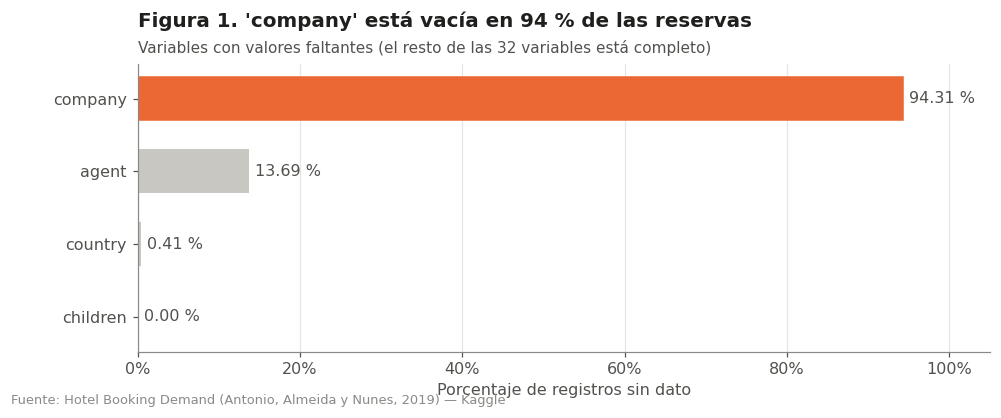

In [ ]:
faltantes = calidad.loc[calidad["nulos"] > 0, "%_nulos"].sort_values()

fig, ax = plt.subplots(figsize=(10, 3.4))
barras = ax.barh(faltantes.index, faltantes.values, color=GRIS_CLARO, height=0.6)
barras[-1].set_color(NARANJA)                       # énfasis en la variable crítica
ax.bar_label(barras, labels=[f"{v:.2f} %" for v in faltantes.values], padding=4, color=TINTA_2)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlim(0, 105)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("Porcentaje de registros sin dato")
titular(ax, "Figura 1. 'company' está vacía en 94 % de las reservas",
        "Variables con valores faltantes (el resto de las 32 variables está completo)")
citar_fuente(fig)
guardar(fig, "fig01_faltantes")
plt.show()

### 5.2 Mecanismo de los faltantes (MCAR, MAR o MNAR)
Un faltante es **MCAR** si su ausencia no depende de nada (completamente al azar), **MAR** si depende de otras variables observadas y
**MNAR** si depende del propio valor no observado. Para distinguirlos se compara, entre registros **con y sin dato**, la tasa de
cancelación y la distribución por hotel, y se aplica una prueba χ² de independencia entre "tener nulo" y `is_canceled`. Si los
registros con nulo se comportan distinto, el faltante **no es MCAR** y no debe imputarse a ciegas.

In [ ]:
filas = []
for col in ["company", "agent", "country", "children"]:
    nulo = df_raw[col].isna()
    _, p, _, _ = stats.chi2_contingency(pd.crosstab(nulo, df_raw["is_canceled"]))
    filas.append({
        "variable": col,
        "n_nulos": nulo.sum(),
        "cancelación_con_nulo_%": df_raw.loc[nulo, "is_canceled"].mean() * 100,
        "cancelación_con_dato_%": df_raw.loc[~nulo, "is_canceled"].mean() * 100,
        "%_Resort_con_nulo": (df_raw.loc[nulo, "hotel"] == "Resort Hotel").mean() * 100,
        "%_Resort_con_dato": (df_raw.loc[~nulo, "hotel"] == "Resort Hotel").mean() * 100,
        "p_valor_χ²": p,
    })
mecanismo = pd.DataFrame(filas).set_index("variable")
display(mecanismo.style.format({"n_nulos": "{:,}", "p_valor_χ²": "{:.2e}"}, precision=1))

print("Canal de distribución de las reservas sin agente (%):")
print((df_raw.loc[df_raw["agent"].isna(), "distribution_channel"].value_counts(normalize=True) * 100).round(1).to_string())

,n_nulos,cancelación_con_nulo_%,cancelación_con_dato_%,%_Resort_con_nulo,%_Resort_con_dato,p_valor_χ²
variable,,,,,,
company,"112,593",38.2,17.5,32.8,45.7,7.45e-258
agent,"16,340",24.7,39.0,50.2,30.9,2.53e-272
country,488,13.7,37.1,95.1,33.3,1.96e-26
children,4,100.0,37.0,0.0,33.6,3.66e-02


Canal de distribución de las reservas sin agente (%):
distribution_channel
Direct      46.70
Corporate   33.90
TA/TO       19.40
Undefined    0.00
GDS          0.00


* **`agent`** (MAR): las reservas sin agente cancelan **24.7 %** frente a **39.0 %** con agente, y se concentran en los canales
  *Direct* (46.7 %) y *Corporate* (33.9 %), con mayor peso del Resort (50.2 % frente a 30.9 %). La ausencia no es aleatoria: indica que la reserva **no pasó por una agencia**. Se codifica como una
  categoría propia (0 = "sin agente") en lugar de imputar un agente.
* **`country`** (MAR): los registros sin país cancelan solo **13.7 %** (frente a 37.1 %) y el **95 % pertenece al Resort Hotel**.
  El faltante depende del hotel (probablemente de su sistema de registro), así que se crea la categoría "Desconocido".
* **`company`** (estructural, cercano a MNAR): el 94 % de las reservas no tiene empresa porque no la hay; la ausencia es en sí
  información ("no es reserva corporativa"): sin empresa se cancela 38.2 % frente a 17.5 % con empresa. La variable se elimina como código, pero su ausencia puede conservarse como indicador binario en la Fase 2.
* **`children`**: 4 registros, todos del City Hotel y cancelados; con n = 4 la prueba no es concluyente y su peso es despreciable,
  así que se imputa con 0.

En `company`, `agent` y `country` la prueba χ² rechaza la independencia con p ≪ 0.001, por lo que **ninguno de los faltantes
relevantes es MCAR**.

**Decisiones de tratamiento.** `company` (empresa que paga la reserva) carece de dato en más del 94 % de los casos, por lo que no aporta
información como código y se elimina. `agent` (13.7 %) indica la ausencia de agencia, por lo que se imputa con 0 = "sin agente". `country` y
`children` tienen muy pocos faltantes y se imputan con "Desconocido" y 0 respectivamente. Los duplicados exactos se analizan en la sección 5.3.

### 5.3 Registros duplicados
El dataset no tiene un identificador de reserva, así que se buscan **filas idénticas en las 32 columnas**. Se cuentan las copias
(sin contar la primera aparición) y se compara su tasa de cancelación y su proporción de depósitos *Non Refund* con las del resto.

In [ ]:
es_dup = df_raw.duplicated()                     # True para la 2.ª aparición en adelante
N_DUP = es_dup.sum()
PCT_DUP = N_DUP / len(df_raw) * 100

duplicados = pd.DataFrame({
    "registros": [N_DUP, (~es_dup).sum()],
    "%_del_total": [PCT_DUP, 100 - PCT_DUP],
    "tasa_cancelación_%": [df_raw.loc[es_dup, "is_canceled"].mean() * 100, df_raw.loc[~es_dup, "is_canceled"].mean() * 100],
    "%_Non_Refund": [(df_raw.loc[es_dup, "deposit_type"] == "Non Refund").mean() * 100,
                     (df_raw.loc[~es_dup, "deposit_type"] == "Non Refund").mean() * 100],
    "%_Groups": [(df_raw.loc[es_dup, "market_segment"] == "Groups").mean() * 100,
                 (df_raw.loc[~es_dup, "market_segment"] == "Groups").mean() * 100],
}, index=["Copias duplicadas", "Registros únicos (1.ª aparición)"])
print(f"Duplicados exactos: {N_DUP:,} ({PCT_DUP:.1f} %) | grupos de filas repetidas: "
      f"{df_raw[df_raw.duplicated(keep=False)].groupby(list(df_raw.columns), dropna=False).ngroups:,}")
duplicados.style.format({"registros": "{:,}"}, precision=1)

Duplicados exactos: 31,994 (26.8 %) | grupos de filas repetidas: 8,171


,registros,%_del_total,tasa_cancelación_%,%_Non_Refund,%_Groups
Copias duplicadas,"31,994",26.8,63.1,42.3,46.5
Registros únicos (1.ª aparición),"87,396",73.2,27.5,1.2,5.7


Hay **31,994 duplicados exactos (26.8 %)**. No se distribuyen al azar: cancelan **≈ 63.1 %** (frente a ≈ 27.5 % de los registros
únicos), el **≈ 42.3 %** tiene depósito *Non Refund* (1.2 % en los únicos) y el 46.5 % es del segmento *Groups* (5.7 %). Esto es consistente con **reservas grupales cargadas en bloque** por
operadores turísticos, por lo que muchos duplicados podrían ser reservas legítimas distintas con atributos idénticos y no errores.

**Riesgo para el modelado:** si filas idénticas quedan a la vez en entrenamiento y en prueba, el modelo "memoriza" esas filas y la
métrica de prueba se infla (fuga por duplicación). En la Fase 2 se debe decidir entre eliminar duplicados o hacer una **partición
por grupos** que mantenga todas las copias de una fila en el mismo lado. En esta fase se conservan para describir el dataset tal
como se publicó.

### 5.4 Incoherencias y valores inválidos
Se define **una regla de validación por fila** a partir del conocimiento del dominio y se cuenta cuántos registros la incumplen.

In [ ]:
huespedes_raw = df_raw["adults"] + df_raw["children"].fillna(0) + df_raw["babies"]
cancelado_por_estado = df_raw["reservation_status"].isin(["Canceled", "No-Show"]).astype(int)

REGLAS = [
    ("Reserva sin huéspedes (adultos + niños + bebés = 0)", huespedes_raw == 0, "Eliminar"),
    ("ADR negativo (adr < 0)", df_raw["adr"] < 0, "Eliminar"),
    ("ADR extremo (adr > 1,000 €)", df_raw["adr"] > 1000, "Eliminar (5,400 €: error de captura)"),
    ("ADR = 0", df_raw["adr"] == 0, "Conservar; revisar en Fase 2 (ver desglose)"),
    ("Estancia de 0 noches", noches_raw == 0, "Conservar (posible day-use); revisar en Fase 2"),
    ("Menores sin adulto (adults = 0 y niños/bebés > 0)", (df_raw["adults"] == 0) & (huespedes_raw > 0), "Conservar; marcar"),
    ("Más de 10 adultos", df_raw["adults"] > 10, "Revisar (grupos o error)"),
    ("9 o más bebés", df_raw["babies"] >= 9, "Tratar como error"),
    ("meal = 'Undefined'", df_raw["meal"] == "Undefined", "Unificar con SC (sin plan)"),
    ("market_segment = 'Undefined'", df_raw["market_segment"] == "Undefined", "Agrupar o eliminar"),
    ("distribution_channel = 'Undefined'", df_raw["distribution_channel"] == "Undefined", "Agrupar o eliminar"),
    ("Habitación asignada ≠ reservada", df_raw["reserved_room_type"] != df_raw["assigned_room_type"], "No es error; es fuga (F)"),
    ("is_canceled incoherente con reservation_status", df_raw["is_canceled"] != cancelado_por_estado, "—"),
]
incoherencias = pd.DataFrame([(r, m.sum(), m.mean() * 100, a) for r, m, a in REGLAS],
                             columns=["Regla de validación", "registros", "%", "Acción propuesta"])
incoherencias.index = range(1, len(incoherencias) + 1)
display(incoherencias.style.format({"registros": "{:,}", "%": "{:.3f}"}))

print("Desglose de ADR = 0 por segmento de mercado:")
adr0 = df_raw.loc[df_raw["adr"] == 0, "market_segment"].value_counts()
print(pd.concat([adr0, adr0 / adr0.sum() * 100], axis=1, keys=["n", "%"]).to_string(float_format=lambda x: f"{x:.1f}"))

,Regla de validación,registros,%,Acción propuesta
1,Reserva sin huéspedes (adultos + niños + bebés = 0),180,0.151,Eliminar
2,ADR negativo (adr < 0),1,0.001,Eliminar
3,"ADR extremo (adr > 1,000 €)",1,0.001,"Eliminar (5,400 €: error de captura)"
4,ADR = 0,"1,959",1.641,Conservar; revisar en Fase 2 (ver desglose)
5,Estancia de 0 noches,715,0.599,Conservar (posible day-use); revisar en Fase 2
6,Menores sin adulto (adults = 0 y niños/bebés > 0),223,0.187,Conservar; marcar
7,Más de 10 adultos,12,0.010,Revisar (grupos o error)
8,9 o más bebés,2,0.002,Tratar como error
9,meal = 'Undefined',"1,169",0.979,Unificar con SC (sin plan)
10,market_segment = 'Undefined',2,0.002,Agrupar o eliminar


Desglose de ADR = 0 por segmento de mercado:
                  n    %
market_segment          
Complementary   680 34.7
Online TA       367 18.7
Offline TA/TO   332 16.9
Groups          252 12.9
Direct          240 12.3
Corporate        82  4.2
Aviation          6  0.3


* Las únicas reglas que justifican **eliminar** registros en esta fase son las imposibles: **180 reservas sin huéspedes**, **1 ADR
  negativo** y **1 ADR de 5,400 €** (182 registros en total, 0.15 %).
* Los **1,959 registros con ADR = 0** no son necesariamente errores: el grupo más grande es *Complementary* (cortesías), aunque también
  aparecen en *Online TA*, *Offline TA/TO* y *Groups*, donde sí son sospechosos. Se conservan y se revisan en la Fase 2,
  especialmente para el problema de regresión del ADR.
* Las **715 estancias de 0 noches**, los **223 menores sin adulto**, los **12 registros con más de 10 adultos** y los **2 con 9 o 10
  bebés** son casos raros que se marcan para su tratamiento en la Fase 2.
* Las categorías **"Undefined"** (1,169 en `meal`, 2 en `market_segment` y 5 en `distribution_channel`) deben unificarse o agruparse.
* Los **14,917 casos de habitación asignada distinta de la reservada** no son errores, pero `assigned_room_type` solo se conoce a la
  llegada, por lo que es **fuga de información**.
* `is_canceled` y `reservation_status` son **perfectamente coherentes** (0 incoherencias): *Canceled* y *No-Show* corresponden a
  `is_canceled = 1`. Por eso mismo `reservation_status` es una copia del objetivo y no puede usarse como predictora.

### 5.5 Limpieza mínima aplicada en la Fase 1
Se aplican solo las decisiones justificadas en las secciones anteriores:
* `children` → 0 en los 4 faltantes; `country` → "Desconocido"; `agent` → 0 = "sin agente"; se elimina `company`.
* Se eliminan las **reservas sin huéspedes** y las tarifas **negativas** o claramente erróneas (ADR > 1,000 €).

Los duplicados y los casos marcados como "revisar" se conservan; su tratamiento definitivo es parte de la Fase 2.

In [ ]:
df = df_raw.copy()

df["children"] = df["children"].fillna(0).astype(int)
df["country"] = df["country"].fillna("Desconocido")
df["agent"] = df["agent"].fillna(0).astype(int)        # 0 = reserva sin agencia
df = df.drop(columns=["company"])

sin_huespedes = (df["adults"] + df["children"] + df["babies"]) == 0
adr_invalido = (df["adr"] < 0) | (df["adr"] > 1000)
print(f"Reservas sin huéspedes eliminadas: {sin_huespedes.sum():,}")
print(f"Reservas con ADR inválido eliminadas: {adr_invalido.sum():,}")

df = df[~sin_huespedes & ~adr_invalido].reset_index(drop=True)
print(f"Registros finales: {len(df):,} ({len(df) / len(df_raw):.2%} del original)")

Reservas sin huéspedes eliminadas: 180
Reservas con ADR inválido eliminadas: 2
Registros finales: 119,208 (99.85% del original)


Quedan **119,208 registros limpios (99.85 % del original)**. La limpieza es mínima a propósito: elimina solo lo imposible y deja las
decisiones discutibles para la Fase 2.

### 5.6 Creación de variables derivadas
A partir de las columnas originales se **crean nuevas variables** que facilitan el análisis:

| Nueva variable | Cálculo | Utilidad |
|---|---|---|
| `fecha_llegada` | año + mes + día | Series de tiempo |
| `mes` | mes en español, categoría ordenada | Ejes con orden natural (Ene → Dic) |
| `temporada` | estación del año (hemisferio norte) | Agrupar estacionalidad |
| `total_noches` | noches fin de semana + entre semana | Duración de la estancia |
| `total_huespedes` | adultos + niños + bebés | Tamaño del grupo |
| `ingreso_estimado` | ADR × total de noches | Valor económico de la reserva |
| `estado` | "Cancelada" / "No cancelada" | Etiquetas legibles en gráficos |
| `rango_anticipacion` | intervalos de `lead_time` (0–7, 8–30, 31–90, 91–180, 181–365, > 365 días) | Variable ordinal para comparar tasas |
| `con_ninos` | niños + bebés > 0 | Perfil familiar |
| `cambio_habitacion` | habitación asignada ≠ reservada | Calidad del servicio (con fuga) |

In [ ]:
MESES_ES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

df["mes_num"] = df["arrival_date_month"].map({m: i + 1 for i, m in enumerate(MESES_EN)})
df["mes"] = pd.Categorical(df["mes_num"].map(dict(enumerate(MESES_ES, start=1))),
                           categories=MESES_ES, ordered=True)
df["fecha_llegada"] = pd.to_datetime(pd.DataFrame({
    "year": df["arrival_date_year"], "month": df["mes_num"], "day": df["arrival_date_day_of_month"]}))

TEMPORADAS = {12: "Invierno", 1: "Invierno", 2: "Invierno", 3: "Primavera", 4: "Primavera", 5: "Primavera",
              6: "Verano", 7: "Verano", 8: "Verano", 9: "Otoño", 10: "Otoño", 11: "Otoño"}
df["temporada"] = pd.Categorical(df["mes_num"].map(TEMPORADAS),
                                 categories=["Primavera", "Verano", "Otoño", "Invierno"], ordered=True)

df["total_noches"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
df["total_huespedes"] = df["adults"] + df["children"] + df["babies"]
df["ingreso_estimado"] = df["adr"] * df["total_noches"]
df["estado"] = np.where(df["is_canceled"] == 1, "Cancelada", "No cancelada")
df["con_ninos"] = (df["children"] + df["babies"]) > 0
df["cambio_habitacion"] = df["reserved_room_type"] != df["assigned_room_type"]
df["rango_anticipacion"] = pd.cut(df["lead_time"], bins=[-1, 7, 30, 90, 180, 365, np.inf],
                                  labels=["0–7 d", "8–30 d", "31–90 d", "91–180 d", "181–365 d", "> 365 d"])

df[["hotel", "fecha_llegada", "mes", "temporada", "total_noches", "total_huespedes",
    "adr", "ingreso_estimado", "estado", "rango_anticipacion", "con_ninos"]].head()

,hotel,fecha_llegada,mes,temporada,total_noches,total_huespedes,adr,ingreso_estimado,estado,rango_anticipacion,con_ninos
0,Resort Hotel,2015-07-01,Jul,Verano,0,2,0.00,0.00,No cancelada,181–365 d,False
1,Resort Hotel,2015-07-01,Jul,Verano,0,2,0.00,0.00,No cancelada,> 365 d,False
2,Resort Hotel,2015-07-01,Jul,Verano,1,1,75.00,75.00,No cancelada,0–7 d,False
3,Resort Hotel,2015-07-01,Jul,Verano,1,1,75.00,75.00,No cancelada,8–30 d,False
4,Resort Hotel,2015-07-01,Jul,Verano,2,2,98.00,196.00,No cancelada,8–30 d,False


Las variables derivadas quedan disponibles en `df`. `total_noches` y `total_huespedes` son **combinaciones lineales** de columnas
originales, por lo que no deben usarse junto con sus componentes en un mismo modelo lineal (redundancia estructural, ver la sección 7.7).

### 5.7 Valores atípicos
Se evalúan las **14 variables cuantitativas** de análisis (las 13 cuantitativas originales no calendáricas más `total_noches`) con
dos criterios: el **rango intercuartílico** (atípico si está fuera de [Q1 − 1.5·IQR, Q3 + 1.5·IQR]) y el **Z-score** (|z| > 3). Se
calcula sobre los datos limpios para que un solo valor erróneo (el ADR de 5,400 €) no distorsione la media ni la desviación estándar.

In [ ]:
VARS_CUANT = ["lead_time", "stays_in_weekend_nights", "stays_in_week_nights", "total_noches", "adults", "children",
              "babies", "previous_cancellations", "previous_bookings_not_canceled", "booking_changes",
              "days_in_waiting_list", "adr", "required_car_parking_spaces", "total_of_special_requests"]

filas = []
for v in VARS_CUANT:
    s = df[v]
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    li, ls = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_iqr = ((s < li) | (s > ls)).sum()
    n_z = (np.abs(stats.zscore(s)) > 3).sum()
    filas.append((v, q1, q3, iqr, li, ls, n_iqr, n_iqr / len(s) * 100, n_z, n_z / len(s) * 100))
atipicos = pd.DataFrame(filas, columns=["variable", "Q1", "Q3", "IQR", "lím_inf", "lím_sup",
                                        "n_IQR", "%_IQR", "n_Z", "%_Z"]).set_index("variable")
atipicos.style.format({"n_IQR": "{:,}", "n_Z": "{:,}", "%_IQR": "{:.2f}", "%_Z": "{:.2f}"}, precision=2)

,Q1,Q3,IQR,lím_inf,lím_sup,n_IQR,%_IQR,n_Z,%_Z
variable,,,,,,,,,
lead_time,18.00,161.00,143.00,-196.50,375.50,"2,981",2.50,"1,453",1.22
stays_in_weekend_nights,0.00,2.00,2.00,-3.00,5.00,258,0.22,"2,181",1.83
stays_in_week_nights,1.00,3.00,2.00,-2.00,6.00,"3,330",2.79,"1,652",1.39
total_noches,2.00,4.00,2.00,-1.00,7.00,"5,225",4.38,"1,703",1.43
adults,2.00,2.00,0.00,2.00,2.00,"29,530",24.77,301,0.25
children,0.00,0.00,0.00,0.00,0.00,"8,590",7.21,"3,729",3.13
babies,0.00,0.00,0.00,0.00,0.00,917,0.77,917,0.77
previous_cancellations,0.00,0.00,0.00,0.00,0.00,"6,479",5.44,317,0.27
previous_bookings_not_canceled,0.00,0.00,0.00,0.00,0.00,"3,612",3.03,933,0.78


* En `adr` hay **3,863 atípicos por IQR (3.24 %)**, todos por encima del límite superior: son tarifas altas reales de temporada alta y
  se conservan. El Z-score marca menos casos porque la distribución es asimétrica y la desviación estándar es grande.
* `lead_time` tiene 2.50 % de atípicos por IQR (más de 375 días de anticipación), coherentes con reservas de grupos.
* **Nota sobre IQR = 0.** En `adults` (Q1 = Q3 = 2, por lo que el 24.8 % de las reservas queda marcado), y en `children`, `babies`, `previous_cancellations`, `previous_bookings_not_canceled`, `booking_changes`,
  `days_in_waiting_list` y `required_car_parking_spaces`, Q1 = Q3 = 0; el IQR es 0 y **cualquier valor distinto de 0 queda
  marcado como atípico** (por ejemplo, 15.1 % en `booking_changes`). En estas variables de conteo con exceso de ceros el criterio IQR no es informativo; es preferible tratarlas
  como "0 frente a > 0" o con agrupaciones (por ejemplo, 0, 1, 2+).

Los diagramas de caja por estado de la reserva muestran dónde están los atípicos de las tres variables clave.

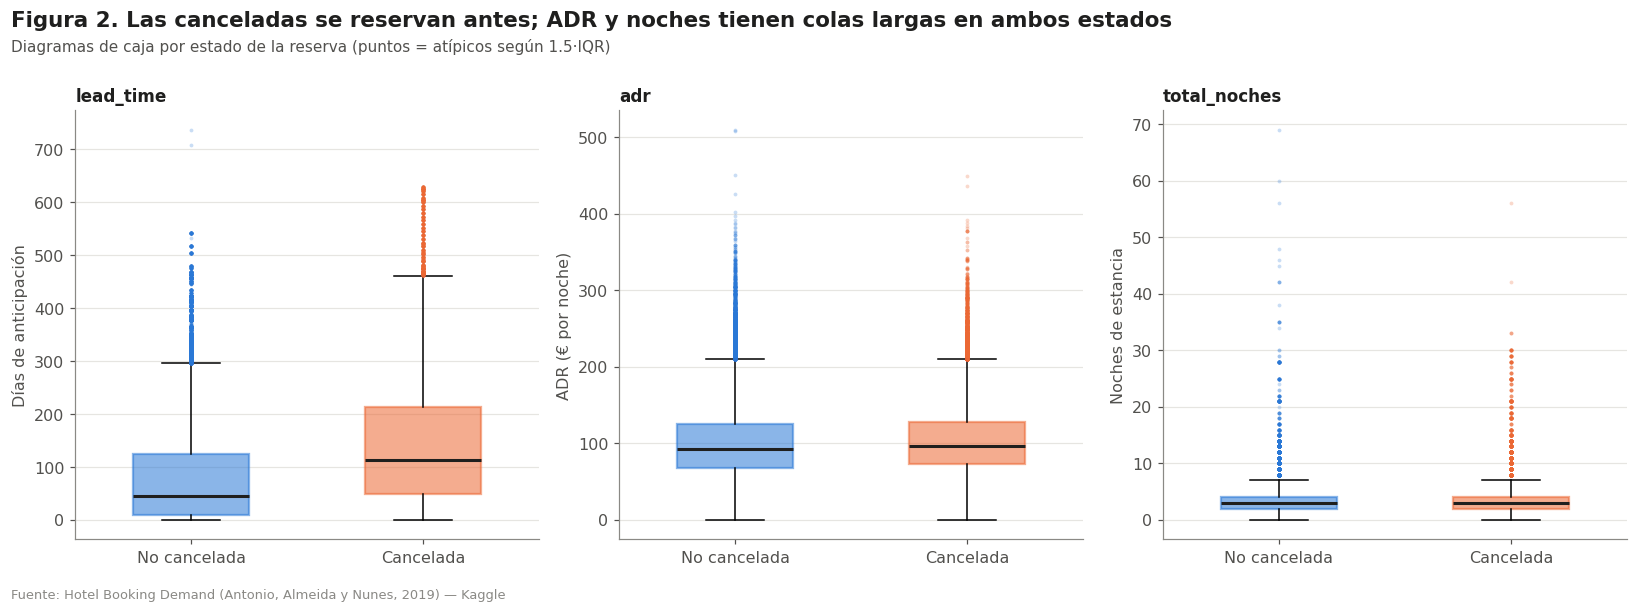

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
estados = ["No cancelada", "Cancelada"]
for ax, (v, etiqueta) in zip(axes, [("lead_time", "Días de anticipación"), ("adr", "ADR (€ por noche)"),
                                    ("total_noches", "Noches de estancia")]):
    caja = ax.boxplot([df.loc[df["estado"] == e, v] for e in estados], tick_labels=estados, patch_artist=True,
                      widths=0.5, medianprops=dict(color=TINTA, lw=2),
                      flierprops=dict(marker="o", markersize=2.5, alpha=0.25, markeredgecolor="none"))
    for parche, flier, e in zip(caja["boxes"], caja["fliers"], estados):
        parche.set(facecolor=COLOR_ESTADO[e], alpha=0.55, edgecolor=COLOR_ESTADO[e], linewidth=1.5)
        flier.set_markerfacecolor(COLOR_ESTADO[e])
    ax.set_ylabel(etiqueta)
    ax.set_title(v, loc="left", fontsize=11, fontweight="bold", color=TINTA)
fig.suptitle("Figura 2. Las canceladas se reservan antes; ADR y noches tienen colas largas en ambos estados",
             x=0.01, ha="left", fontsize=14, fontweight="bold", color=TINTA, y=1.04)
fig.text(0.01, 0.965, "Diagramas de caja por estado de la reserva (puntos = atípicos según 1.5·IQR)", fontsize=10, color=TINTA_2)
fig.tight_layout()
citar_fuente(fig)
guardar(fig, "fig02_atipicos_caja")
plt.show()

La caja de `lead_time` de las canceladas está claramente desplazada hacia arriba: la anticipación es la diferencia más visible entre
estados. En `adr` y `total_noches` las cajas son parecidas y los atípicos están en la cola superior de ambos grupos, lo que confirma
que son valores extremos legítimos (estancias largas, tarifas de temporada alta) más que errores.

## 6. Análisis univariado

### 6.1 Medidas de tendencia central, dispersión y forma
Para las 14 variables cuantitativas se calculan, sobre los **119,208 registros limpios**: media, mediana, moda, desviación estándar,
IQR, coeficiente de variación (CV %), asimetría, curtosis (exceso), mínimo y máximo.

In [ ]:
def resumen_cuantitativo(data, variables):
    d = data[variables]
    r = pd.DataFrame({
        "media": d.mean(), "mediana": d.median(), "moda": d.mode().iloc[0], "desv_est": d.std(),
        "IQR": d.quantile(0.75) - d.quantile(0.25),
    })
    r["CV_%"] = r["desv_est"] / r["media"] * 100
    r["asimetría"] = d.skew()
    r["curtosis"] = d.kurt()
    r["mín"] = d.min()
    r["máx"] = d.max()
    return r

univariado = resumen_cuantitativo(df, VARS_CUANT)
univariado

,media,mediana,moda,desv_est,IQR,CV_%,asimetría,curtosis,mín,máx
lead_time,104.11,69.00,0.00,106.88,143.00,102.66,1.35,1.69,0.00,737.00
stays_in_weekend_nights,0.93,1.00,0.00,1.00,2.00,107.34,1.32,6.37,0.00,19.00
stays_in_week_nights,2.50,2.00,2.00,1.90,2.00,75.91,2.75,22.25,0.00,50.00
total_noches,3.43,3.00,2.00,2.54,2.00,74.15,3.19,26.49,0.00,69.00
adults,1.86,2.00,2.00,0.58,0.00,30.94,18.77,"1,392.49",0.00,55.00
children,0.10,0.00,0.00,0.40,0.00,383.33,4.11,18.64,0.00,10.00
babies,0.01,0.00,0.00,0.10,0.00,"1,224.87",24.63,"1,631.47",0.00,10.00
previous_cancellations,0.09,0.00,0.00,0.84,0.00,969.04,24.44,673.21,0.00,26.00
previous_bookings_not_canceled,0.14,0.00,0.00,1.50,0.00,"1,092.90",23.54,766.96,0.00,72.00
booking_changes,0.22,0.00,0.00,0.64,0.00,291.84,5.50,63.45,0.00,18.00


* `lead_time` tiene media (≈ 104 días) muy superior a la mediana (69 días) y asimetría positiva: la mayoría reserva con pocas
  semanas, pero existe una cola larga de reservas con muchos meses de anticipación.
* `adr` tiene media ≈ 102 € y mediana ≈ 95 €, con asimetría moderada (≈ 1.0) tras la limpieza. Su **moda es 62 €**, la misma tarifa
  de la franja de reservas en bloque que se analiza en la sección 7.5.
* `adults` tiene moda y mediana 2 y poca variación (CV ≈ 31 %), pero curtosis extrema por unos pocos grupos grandes.
* Las variables de conteo (`babies`, `previous_cancellations`, `days_in_waiting_list`, `required_car_parking_spaces`, etc.) tienen
  moda y mediana 0, CV muy alto y curtosis extrema: casi todos los valores son 0 con unos pocos extremos. Para ellas la **mediana**
  describe mejor el caso típico que la media, y en la Fase 2 conviene binarizarlas o transformarlas.

**Efecto de un solo valor erróneo.** Se comparan los momentos del ADR antes y después de la limpieza.

In [ ]:
momentos_adr = pd.DataFrame({
    "Antes de limpiar (crudo)": [len(df_raw), df_raw["adr"].mean(), df_raw["adr"].std(), df_raw["adr"].max(),
                                 df_raw["adr"].skew(), df_raw["adr"].kurt()],
    "Después de limpiar": [len(df), df["adr"].mean(), df["adr"].std(), df["adr"].max(), df["adr"].skew(), df["adr"].kurt()],
}, index=["n", "media", "desv_est", "máx", "asimetría", "curtosis"])
momentos_adr

,Antes de limpiar (crudo),Después de limpiar
n,"119,390.00","119,208.00"
media,101.83,101.93
desv_est,50.54,48.04
máx,"5,400.00",510.00
asimetría,10.53,1.03
curtosis,"1,013.19",2.15


Con los datos crudos el ADR tiene **asimetría 10.53 y curtosis ≈ 1,013**; tras eliminar 182 registros (sobre todo el ADR de
5,400 € y el negativo) bajan a ≈ 1.03 y ≈ 2.15. La media apenas cambia, pero los momentos de orden 3 y 4 son extremadamente sensibles
a un solo valor erróneo: por eso la limpieza de inválidos debe preceder a cualquier descripción de la forma de una distribución.

### 6.2 Distribución de las variables cuantitativas clave
Los histogramas de `lead_time`, `adr` y `total_noches` muestran la forma completa de la distribución; las líneas de **media** y
**mediana** hacen visible la asimetría (la media se aleja de la mediana hacia la cola larga). Para la legibilidad, el eje X se corta
en el percentil 99.5 (los valores por encima siguen incluidos en las estadísticas).

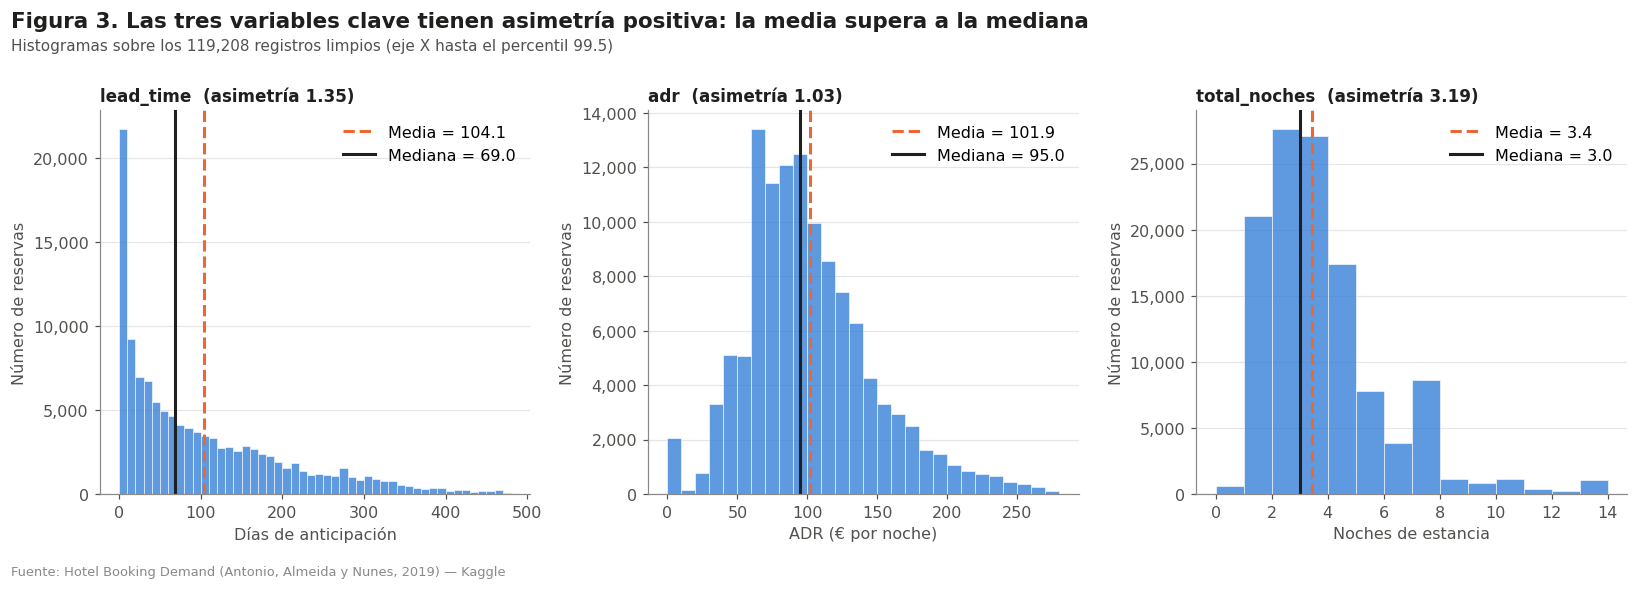

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, (v, etiqueta, ancho) in zip(axes, [("lead_time", "Días de anticipación", 10),
                                           ("adr", "ADR (€ por noche)", 10),
                                           ("total_noches", "Noches de estancia", 1)]):
    s = df[v]
    tope = s.quantile(0.995)
    ax.hist(s[s <= tope], bins=np.arange(0, tope + ancho, ancho), color=AZUL, alpha=0.75, edgecolor="white", linewidth=0.5)
    ax.axvline(s.mean(), color=NARANJA, lw=2, ls="--", label=f"Media = {s.mean():,.1f}")
    ax.axvline(s.median(), color=TINTA, lw=2, label=f"Mediana = {s.median():,.1f}")
    ax.set_xlabel(etiqueta); ax.set_ylabel("Número de reservas")
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
    ax.legend(loc="upper right")
    ax.set_title(f"{v}  (asimetría {s.skew():.2f})", loc="left", fontsize=11, fontweight="bold", color=TINTA)
fig.suptitle("Figura 3. Las tres variables clave tienen asimetría positiva: la media supera a la mediana",
             x=0.01, ha="left", fontsize=14, fontweight="bold", color=TINTA, y=1.04)
fig.text(0.01, 0.965, "Histogramas sobre los 119,208 registros limpios (eje X hasta el percentil 99.5)", fontsize=10, color=TINTA_2)
fig.tight_layout()
citar_fuente(fig)
guardar(fig, "fig03_histogramas")
plt.show()

Las tres distribuciones son **asimétricas a la derecha**. `lead_time` decrece casi de forma exponencial desde 0; `adr` es
unimodal alrededor de 60–120 € con una cola de tarifas altas; `total_noches` se concentra en 1 a 4 noches con picos en estancias de
una semana (7 noches) típicas del Resort. En la Fase 2 una transformación logarítmica puede ayudar a los modelos sensibles a la escala.

### 6.3 Tablas de frecuencia de las variables cualitativas
Para cada variable cualitativa se presenta la frecuencia absoluta (n) y relativa (%). En `country` se muestran los 10 países más
frecuentes y el resto se agrupa en "Otros"; los meses y años se presentan en su orden natural.

In [ ]:
def top_n(s, n=10, otros="Otros"):
    top = s.value_counts().index[:n]
    return s.where(s.isin(top), otros)

def tabla_frecuencia(s, orden=None):
    n = s.value_counts()
    if orden is not None:
        n = n.reindex([o for o in orden if o in n.index])
    return pd.DataFrame({"n": n, "%": n / n.sum() * 100})

VARS_CUAL = ["hotel", "is_canceled", "deposit_type", "customer_type", "market_segment", "distribution_channel",
             "meal", "is_repeated_guest", "reserved_room_type", "assigned_room_type", "country",
             "arrival_date_month", "arrival_date_year", "reservation_status"]

for col in VARS_CUAL:
    if col == "country":
        t = tabla_frecuencia(top_n(df[col]))
        t = pd.concat([t.drop("Otros"), t.loc[["Otros"]]])
        titulo = "country (top 10 + Otros)"
    elif col == "arrival_date_month":
        t, titulo = tabla_frecuencia(df[col], MESES_EN), col
    elif col in ["arrival_date_year", "is_canceled", "is_repeated_guest"]:
        t, titulo = tabla_frecuencia(df[col]).sort_index(), col
    else:
        t, titulo = tabla_frecuencia(df[col]), col
    print(f"--- {titulo} ---")
    print(t.to_string(formatters={"n": "{:,}".format, "%": "{:.1f}".format}), end="\n\n")

--- hotel ---
                  n    %
hotel                   
City Hotel   79,162 66.4
Resort Hotel 40,046 33.6

--- is_canceled ---
                 n    %
is_canceled            
0           75,010 62.9
1           44,198 37.1

--- deposit_type ---
                   n    %
deposit_type             
No Deposit   104,460 87.6
Non Refund    14,586 12.2
Refundable       162  0.1

--- customer_type ---
                     n    %
customer_type              
Transient       89,475 75.1
Transient-Party 25,087 21.0
Contract         4,072  3.4
Group              574  0.5

--- market_segment ---
                    n    %
market_segment            
Online TA      56,408 47.3
Offline TA/TO  24,181 20.3
Groups         19,790 16.6
Direct         12,582 10.6
Corporate       5,282  4.4
Complementary     728  0.6
Aviation          235  0.2
Undefined           2  0.0

--- distribution_channel ---
                          n    %
distribution_channel            
TA/TO                97,749 82.0
Dir

* **Desbalance en el objetivo:** 62.9 % no canceladas frente a 37.1 % canceladas; el **City Hotel** concentra 2 de cada 3 reservas.
* **Concentración en pocas categorías:** *No Deposit* (≈ 88 %), *Transient* (≈ 75 %), *Online TA* (≈ 47 %), *TA/TO* (≈ 82 %), *BB*
  (≈ 77 %), habitación *A* (≈ 72 %) y **Portugal (≈ 41 %)**. Las categorías minoritarias (*Aviation*, *Undefined*, *GDS*, habitaciones
  *L*, *Refundable*) tienen muy pocos registros y deberán **agruparse** en la Fase 2.
* Solo **3 %** de los clientes son recurrentes (`is_repeated_guest`).
* `arrival_date_year` muestra cobertura incompleta en 2015 (desde julio) y 2017 (hasta agosto): las comparaciones anuales deben
  hacerse con cuidado; las mensuales promedian años distintos.
* `reservation_status` reproduce `is_canceled` (Check-Out = no cancelada; Canceled + No-Show = cancelada).

## 7. Análisis bivariado y multivariado

Esta sección relaciona cada variable con los dos objetivos. Primero se describe la cancelación por hotel y se comparan los
estados; después se visualizan las relaciones clave, se miden correlaciones (Pearson y Spearman), se analizan diagramas de
dispersión, se aplican pruebas χ² con V de Cramér a las cualitativas y se cierra con tablas multivariadas y el análisis del ADR.

### 7.1 Tasa de cancelación por hotel

In [ ]:
TASA_GLOBAL = df["is_canceled"].mean() * 100

resumen_hotel = df.groupby("hotel").agg(
    reservas=("is_canceled", "size"),
    canceladas=("is_canceled", "sum"),
    tasa_cancelacion_pct=("is_canceled", lambda s: s.mean() * 100),
    adr_medio=("adr", "mean"),
    lead_time_mediana=("lead_time", "median"),
    noches_promedio=("total_noches", "mean"),
)
print(f"Tasa global de cancelación: {TASA_GLOBAL:.1f} %")
resumen_hotel

Tasa global de cancelación: 37.1 %


,reservas,canceladas,tasa_cancelacion_pct,adr_medio,lead_time_mediana,noches_promedio
hotel,,,,,,
City Hotel,79162,33078,41.79,105.44,74.00,2.97
Resort Hotel,40046,11120,27.77,94.99,57.00,4.32


La tasa global de cancelación es **37.1 %**: **41.8 % en el City Hotel** y **27.8 % en el Resort Hotel**. El City Hotel tiene,
además, una tarifa media más alta y estancias más cortas; el Resort tiene anticipaciones menores y estancias más largas.

### 7.2 Comparación entre reservas canceladas y no canceladas
Se comparan medianas y medias de las variables cuantitativas entre los dos estados para identificar qué variables las separan.

In [ ]:
comparacion = df.groupby("estado")[["lead_time", "adr", "total_noches", "booking_changes",
                                    "total_of_special_requests", "previous_cancellations"]].median().T
comparacion["media_cancelada"] = df[df["is_canceled"] == 1][comparacion.index].mean()
comparacion["media_no_cancelada"] = df[df["is_canceled"] == 0][comparacion.index].mean()
comparacion.columns = ["mediana_cancelada", "mediana_no_cancelada", "media_cancelada", "media_no_cancelada"]
comparacion

,mediana_cancelada,mediana_no_cancelada,media_cancelada,media_no_cancelada
lead_time,113.00,45.00,144.89,80.08
adr,96.30,92.70,104.90,100.17
total_noches,3.00,3.00,3.49,3.39
booking_changes,0.00,0.00,0.10,0.29
total_of_special_requests,0.00,1.00,0.33,0.71
previous_cancellations,0.00,0.00,0.21,0.02


Las reservas canceladas tienen una anticipación (`lead_time`) mediana notablemente mayor que las no canceladas
y, en promedio, menos solicitudes especiales y menos cambios en la reserva. Estas diferencias se exploran visualmente a continuación.

### 7.3 Visualización de las relaciones con la cancelación

#### 7.3.1 ¿Qué tan grande es el problema de cancelación?
Se usan dos paneles: el volumen (conteos absolutos) y la proporción (tasa), para no mezclarlos en un gráfico de doble eje.

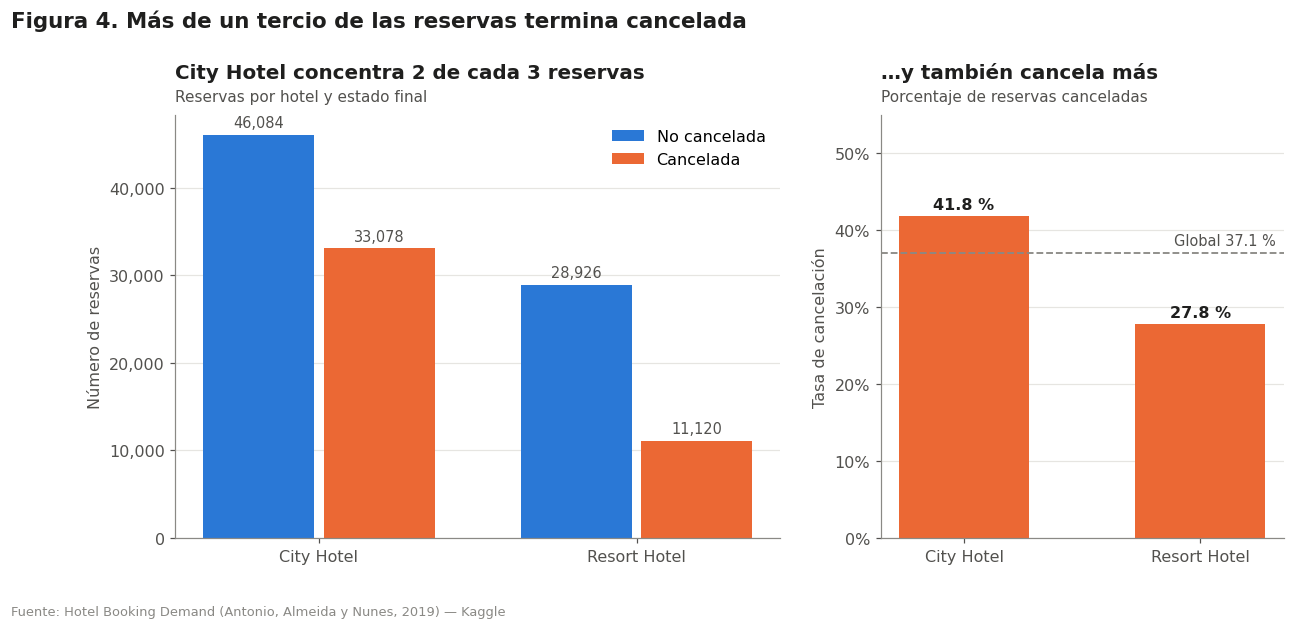

In [ ]:
conteo = pd.crosstab(df["hotel"], df["estado"])[["No cancelada", "Cancelada"]]
tasa_hotel = df.groupby("hotel")["is_canceled"].mean() * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.5, 1]})

x = np.arange(len(conteo)); ancho = 0.38
for i, estado in enumerate(conteo.columns):
    b = ax1.bar(x + (i - 0.5) * ancho, conteo[estado], width=ancho - 0.03,
                color=COLOR_ESTADO[estado], label=estado)
    ax1.bar_label(b, labels=[f"{v:,.0f}" for v in conteo[estado]], padding=3, color=TINTA_2, fontsize=9.5)
ax1.set_xticks(x, conteo.index)
ax1.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax1.set_ylabel("Número de reservas")
ax1.legend(loc="upper right")
titular(ax1, "City Hotel concentra 2 de cada 3 reservas", "Reservas por hotel y estado final")

b = ax2.bar(tasa_hotel.index, tasa_hotel.values, color=NARANJA, width=0.55)
ax2.bar_label(b, labels=[f"{v:.1f} %" for v in tasa_hotel], padding=3, color=TINTA, fontweight="bold")
ax2.axhline(TASA_GLOBAL, color=GRIS, ls="--", lw=1.2)
ax2.text(1.32, TASA_GLOBAL + 1, f"Global {TASA_GLOBAL:.1f} %", color=TINTA_2, ha="right", fontsize=9.5)
ax2.yaxis.set_major_formatter(mtick.PercentFormatter())
ax2.set_ylim(0, 55)
ax2.set_ylabel("Tasa de cancelación")
titular(ax2, "…y también cancela más", "Porcentaje de reservas canceladas")

fig.suptitle("Figura 4. Más de un tercio de las reservas termina cancelada",
             x=0.01, ha="left", fontsize=14, fontweight="bold", color=TINTA, y=1.07)
citar_fuente(fig)
guardar(fig, "fig04_cancelacion_hotel")
plt.show()

Aproximadamente **37 % de todas las reservas se cancela**. El *City Hotel* no solo recibe más reservas, sino que
cancela en mayor proporción (≈ 42 %) que el *Resort Hotel* (≈ 28 %). Se usaron dos paneles porque responden a dos preguntas
distintas: el volumen (conteos absolutos) y la proporción (tasa); mezclarlos en un solo gráfico con doble eje confundiría al lector.

#### 7.3.2 ¿Cómo evoluciona la demanda en el tiempo?
Una serie mensual por hotel muestra la tendencia y la estacionalidad de las llegadas.

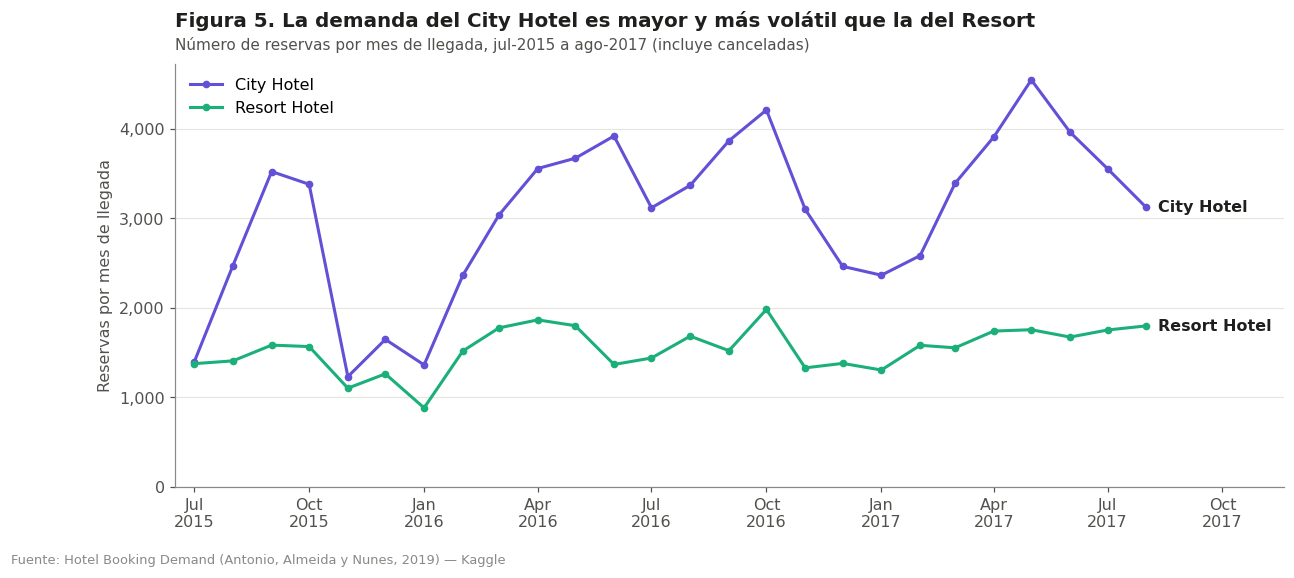

In [ ]:
serie = (df.groupby([pd.Grouper(key="fecha_llegada", freq="MS"), "hotel"]).size()
           .unstack("hotel"))

fig, ax = plt.subplots(figsize=(13, 5))
for hotel in serie.columns:
    ax.plot(serie.index, serie[hotel], color=COLOR_HOTEL[hotel], marker="o", markersize=4, label=hotel)
    ax.annotate(hotel, xy=(serie.index[-1], serie[hotel].iloc[-1]), xytext=(8, 0),
                textcoords="offset points", va="center", color=TINTA, fontweight="bold")
ax.set_ylim(0)
ax.set_xlim(serie.index[0] - pd.Timedelta(days=15), serie.index[-1] + pd.Timedelta(days=110))
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b\n%Y"))
ax.set_ylabel("Reservas por mes de llegada")
ax.legend(loc="upper left")
titular(ax, "Figura 5. La demanda del City Hotel es mayor y más volátil que la del Resort",
        "Número de reservas por mes de llegada, jul-2015 a ago-2017 (incluye canceladas)")
citar_fuente(fig)
guardar(fig, "fig05_demanda_mensual")
plt.show()

La serie de tiempo muestra la **estacionalidad**: la demanda cae en los meses de invierno (noviembre a enero) y
sube en primavera y verano. El *City Hotel* tiene picos más pronunciados. Se eligió un gráfico de **líneas** porque el eje X es
temporal y continuo; las etiquetas directas al final de cada línea evitan que el lector tenga que ir y venir a la leyenda.

Además del volumen, se compara la **tasa de cancelación por mes de llegada** de cada hotel frente al promedio global.

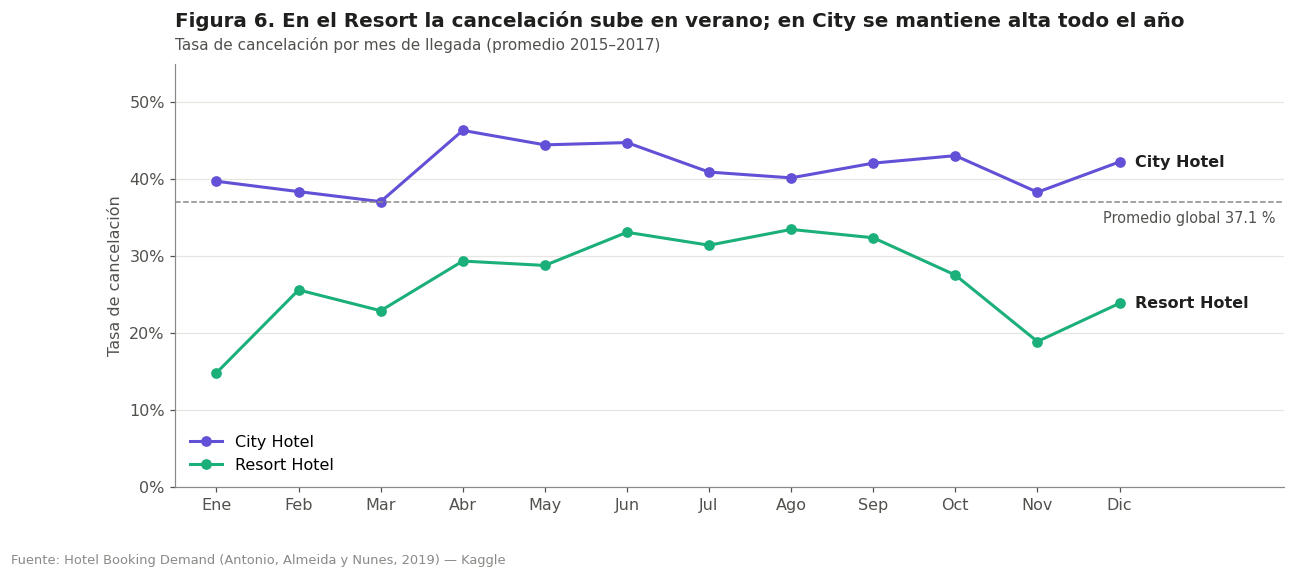

In [ ]:
tasa_mes = df.pivot_table(index="mes", columns="hotel", values="is_canceled", aggfunc="mean", observed=True) * 100

fig, ax = plt.subplots(figsize=(13, 5))
for hotel in tasa_mes.columns:
    ax.plot(tasa_mes.index.astype(str), tasa_mes[hotel], color=COLOR_HOTEL[hotel], marker="o", markersize=6, label=hotel)
    ax.annotate(f"{hotel}", xy=(11, tasa_mes[hotel].iloc[-1]), xytext=(10, 0),
                textcoords="offset points", va="center", color=TINTA, fontweight="bold")
ax.axhline(TASA_GLOBAL, color=GRIS, ls="--", lw=1)
ax.text(12.9, TASA_GLOBAL - 2.8, f"Promedio global {TASA_GLOBAL:.1f} %", color=TINTA_2, fontsize=9.5, ha="right")
ax.set_ylim(0, 55); ax.set_xlim(-0.5, 13)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylabel("Tasa de cancelación")
ax.legend(loc="lower left")
titular(ax, "Figura 6. En el Resort la cancelación sube en verano; en City se mantiene alta todo el año",
        "Tasa de cancelación por mes de llegada (promedio 2015–2017)")
citar_fuente(fig)
guardar(fig, "fig06_cancelacion_mes")
plt.show()

El *City Hotel* mantiene una cancelación cercana o superior al 40 % casi todo el año, mientras que el *Resort*
muestra un patrón estacional con picos en los meses de verano (junio–agosto) y mínimos en invierno. Esto sugiere que las
estrategias de mitigación (sobreventa controlada, políticas de depósito) deberían ser **diferentes por hotel y por temporada**.

#### 7.3.3 ¿La anticipación de la reserva influye en la cancelación?
Se compara la distribución de `lead_time` por estado (histograma de densidad) y la tasa de cancelación por rango de anticipación.

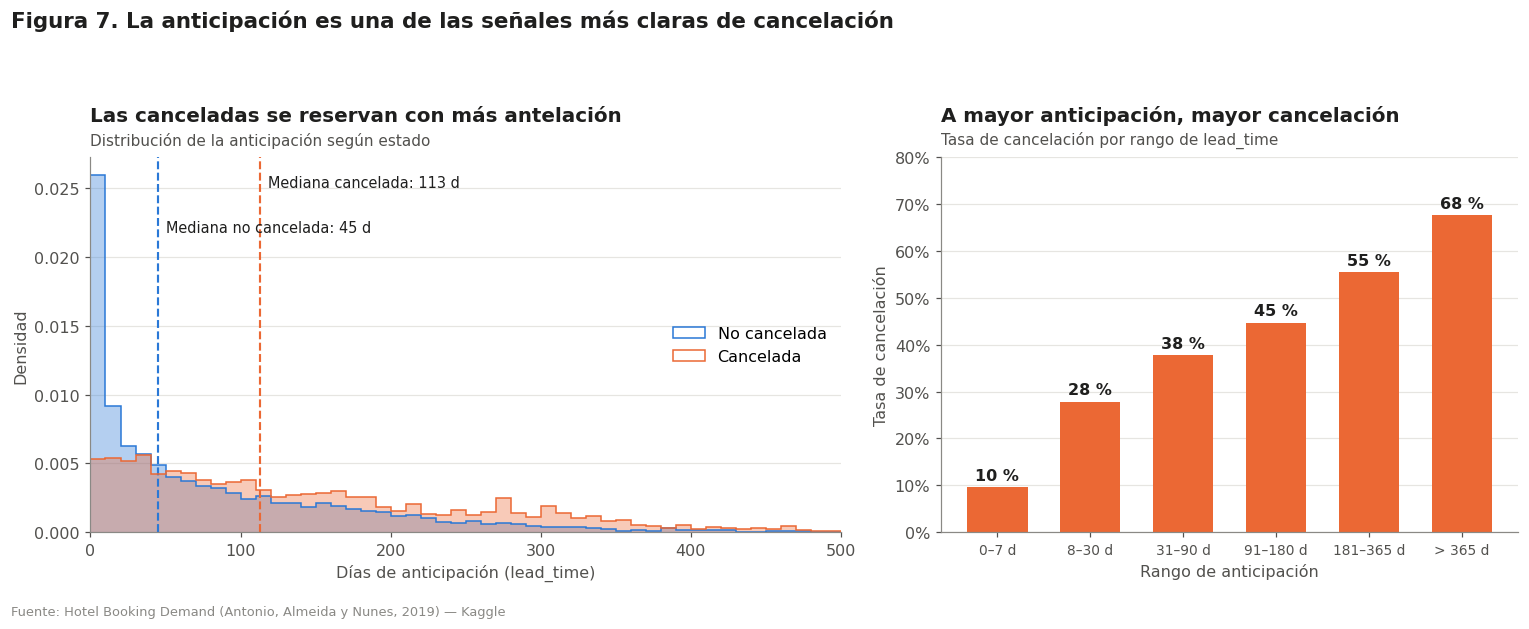

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.3, 1]})

bins = np.arange(0, 501, 10)
for estado in ["No cancelada", "Cancelada"]:
    datos = df.loc[df["estado"] == estado, "lead_time"]
    ax1.hist(datos, bins=bins, density=True, histtype="stepfilled", alpha=0.35, color=COLOR_ESTADO[estado])
    ax1.hist(datos, bins=bins, density=True, histtype="step", lw=1.8, color=COLOR_ESTADO[estado], label=estado)
    med = datos.median()
    ax1.axvline(med, color=COLOR_ESTADO[estado], ls="--", lw=1.4)
    ax1.text(med + 5, ax1.get_ylim()[1] * (0.92 if estado == "Cancelada" else 0.80),
             f"Mediana {estado.lower()}: {med:.0f} d", color=TINTA, fontsize=9.5)
ax1.set_xlim(0, 500)
ax1.set_xlabel("Días de anticipación (lead_time)"); ax1.set_ylabel("Densidad")
ax1.legend(loc="center right")
titular(ax1, "Las canceladas se reservan con más antelación", "Distribución de la anticipación según estado")

tasa_lt = df.groupby("rango_anticipacion", observed=True)["is_canceled"].agg(["mean", "size"])
b = ax2.bar(tasa_lt.index.astype(str), tasa_lt["mean"] * 100, color=NARANJA, width=0.65)
ax2.bar_label(b, labels=[f"{v:.0f} %" for v in tasa_lt["mean"] * 100], padding=3, color=TINTA, fontweight="bold")
ax2.yaxis.set_major_formatter(mtick.PercentFormatter()); ax2.set_ylim(0, 80)
ax2.set_xlabel("Rango de anticipación"); ax2.set_ylabel("Tasa de cancelación")
ax2.tick_params(axis="x", labelsize=9)
titular(ax2, "A mayor anticipación, mayor cancelación", "Tasa de cancelación por rango de lead_time")

fig.suptitle("Figura 7. La anticipación es una de las señales más claras de cancelación",
             x=0.01, ha="left", fontsize=14, fontweight="bold", color=TINTA, y=1.07)
fig.tight_layout()
citar_fuente(fig)
guardar(fig, "fig07_anticipacion")
plt.show()

El **histograma** (izquierda) muestra que la distribución de las reservas no canceladas se concentra en pocos
días de anticipación, mientras que la de las canceladas está desplazada hacia la derecha. La variable derivada `rango_anticipacion`
(derecha) permite leerlo como tasa: las reservas de última semana casi no se cancelan (≈ 10 %), mientras que las hechas con más de
6 meses superan el 50 %. Para el hotel, **una reserva lejana es una reserva incierta**.

#### 7.3.4 ¿Cómo varía la tarifa (ADR) por hotel y por mes?
Se usan solo las reservas no canceladas con ADR > 0, que representan tarifas efectivamente cobradas.

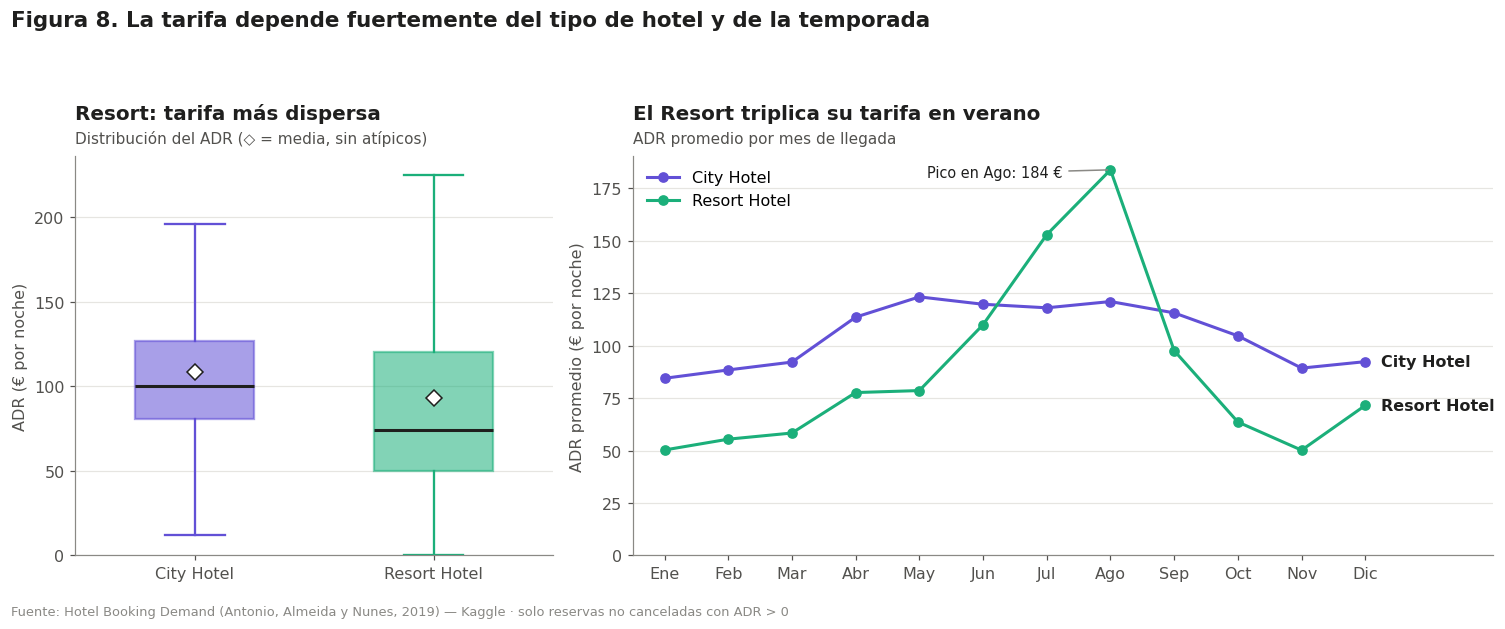

In [ ]:
validas = df[(df["is_canceled"] == 0) & (df["adr"] > 0)]
adr_mes = validas.pivot_table(index="mes", columns="hotel", values="adr", aggfunc="mean", observed=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.8]})

hoteles = ["City Hotel", "Resort Hotel"]
caja = ax1.boxplot([validas.loc[validas["hotel"] == h, "adr"] for h in hoteles], tick_labels=hoteles,
                   patch_artist=True, widths=0.5, showfliers=False, showmeans=True,
                   medianprops=dict(color=TINTA, lw=2),
                   meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor=TINTA, markersize=7))
for parche, h in zip(caja["boxes"], hoteles):
    parche.set(facecolor=COLOR_HOTEL[h], alpha=0.55, edgecolor=COLOR_HOTEL[h], linewidth=1.5)
for elem in ["whiskers", "caps"]:
    for linea, h in zip(caja[elem], np.repeat(hoteles, 2)):
        linea.set(color=COLOR_HOTEL[h], linewidth=1.5)
ax1.set_ylabel("ADR (€ por noche)"); ax1.set_ylim(0)
titular(ax1, "Resort: tarifa más dispersa", "Distribución del ADR (◇ = media, sin atípicos)")

for h in hoteles:
    ax2.plot(adr_mes.index.astype(str), adr_mes[h], color=COLOR_HOTEL[h], marker="o", markersize=6, label=h)
    ax2.annotate(h, xy=(11, adr_mes[h].iloc[-1]), xytext=(10, 0), textcoords="offset points",
                 va="center", color=TINTA, fontweight="bold")
pico = adr_mes["Resort Hotel"].idxmax()
ax2.annotate(f"Pico en {pico}: {adr_mes['Resort Hotel'].max():.0f} €",
             xy=(MESES_ES.index(pico), adr_mes["Resort Hotel"].max()), xytext=(-120, -5),
             textcoords="offset points", color=TINTA, fontsize=9.5,
             arrowprops=dict(arrowstyle="-", color=GRIS))
ax2.set_ylim(0); ax2.set_xlim(-0.5, 13)
ax2.set_ylabel("ADR promedio (€ por noche)")
ax2.legend(loc="upper left")
titular(ax2, "El Resort triplica su tarifa en verano", "ADR promedio por mes de llegada")

fig.suptitle("Figura 8. La tarifa depende fuertemente del tipo de hotel y de la temporada",
             x=0.01, ha="left", fontsize=14, fontweight="bold", color=TINTA, y=1.07)
fig.tight_layout()
citar_fuente(fig, FUENTE + " · solo reservas no canceladas con ADR > 0")
guardar(fig, "fig08_adr_hotel_mes")
plt.show()

El **diagrama de caja** resume la distribución del ADR (mediana, cuartiles, rango) y permite comparar los dos
hoteles de un vistazo: el *City Hotel* tiene una tarifa típica más alta y estable; el *Resort* es más disperso. El gráfico de
**líneas** explica esa dispersión: el *Resort* casi triplica su tarifa en julio–agosto respecto al invierno (temporada de playa), mientras que el *City
Hotel* tiene un comportamiento más uniforme con su máximo en primavera. Esto indica que **cancelar en verano en el Resort tiene
un costo económico mayor**.

#### 7.3.5 ¿De dónde provienen los clientes y quiénes cancelan más?
Se comparan el volumen y la tasa de cancelación de los 10 países con más reservas, con eje Y compartido.

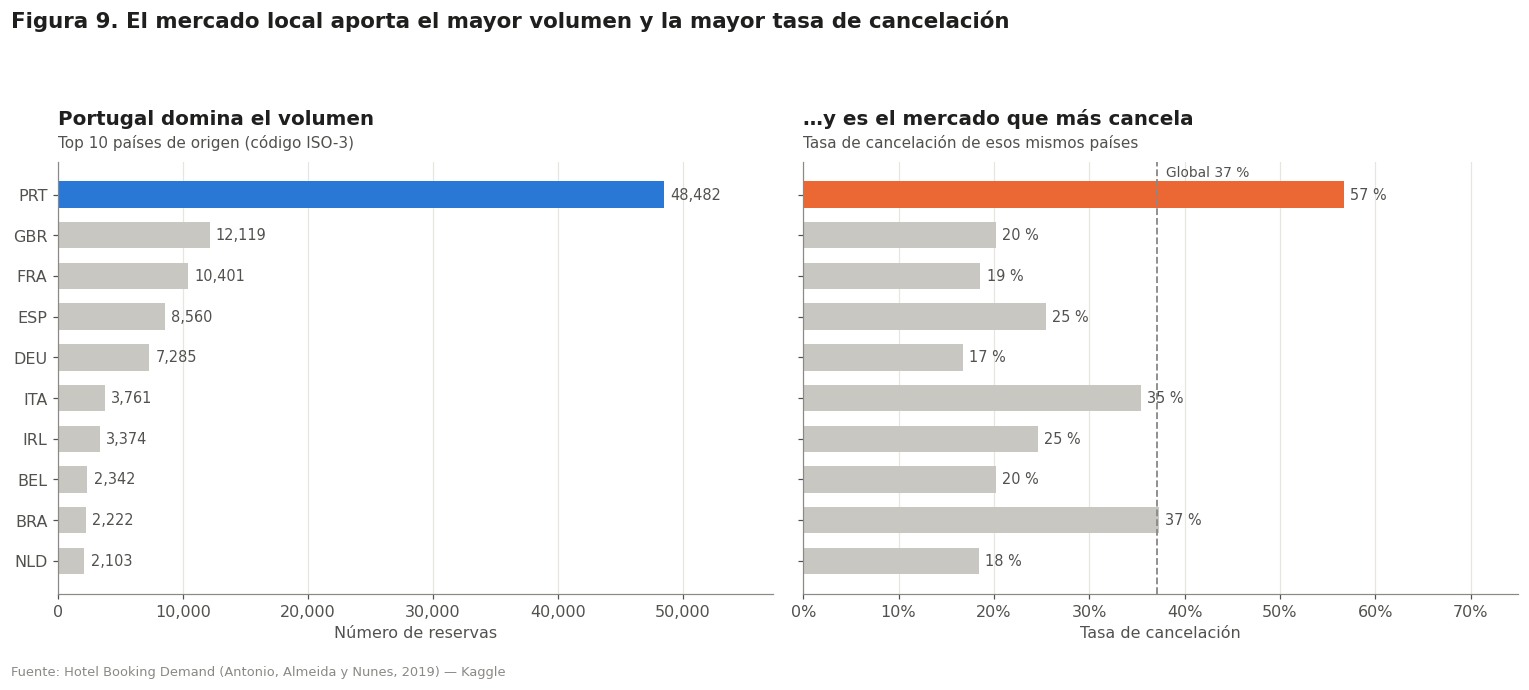

In [ ]:
top_paises = df["country"].value_counts().head(10)
tasa_pais = df[df["country"].isin(top_paises.index)].groupby("country")["is_canceled"].mean() * 100
orden = top_paises.sort_values().index

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)

colores = [AZUL if p == "PRT" else GRIS_CLARO for p in orden]
b1 = ax1.barh(orden, top_paises[orden], color=colores, height=0.65)
ax1.bar_label(b1, labels=[f"{v:,.0f}" for v in top_paises[orden]], padding=4, color=TINTA_2, fontsize=9.5)
ax1.set_xlim(0, top_paises.max() * 1.18)
ax1.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax1.grid(axis="x"); ax1.grid(axis="y", visible=False)
ax1.set_xlabel("Número de reservas")
titular(ax1, "Portugal domina el volumen", "Top 10 países de origen (código ISO-3)")

colores2 = [NARANJA if p == "PRT" else GRIS_CLARO for p in orden]
b2 = ax2.barh(orden, tasa_pais[orden], color=colores2, height=0.65)
ax2.bar_label(b2, labels=[f"{v:.0f} %" for v in tasa_pais[orden]], padding=4, color=TINTA_2, fontsize=9.5)
ax2.axvline(TASA_GLOBAL, color=GRIS, ls="--", lw=1.2)
ax2.text(TASA_GLOBAL + 1, 9.45, f"Global {TASA_GLOBAL:.0f} %", color=TINTA_2, fontsize=9)
ax2.xaxis.set_major_formatter(mtick.PercentFormatter()); ax2.set_xlim(0, 75)
ax2.grid(axis="x"); ax2.grid(axis="y", visible=False)
ax2.set_xlabel("Tasa de cancelación")
titular(ax2, "…y es el mercado que más cancela", "Tasa de cancelación de esos mismos países")

fig.suptitle("Figura 9. El mercado local aporta el mayor volumen y la mayor tasa de cancelación",
             x=0.01, ha="left", fontsize=14, fontweight="bold", color=TINTA, y=1.07)
fig.tight_layout()
citar_fuente(fig)
guardar(fig, "fig09_paises")
plt.show()

Portugal (PRT) aporta cerca del 40 % de las reservas y presenta una tasa de cancelación muy superior al resto de
mercados europeos, que se mantienen por debajo del promedio global. Los dos paneles **comparten el eje Y** (mismo orden de países),
aplicando el principio de proximidad de la Gestalt: el lector compara volumen y tasa de cada país en la misma fila. El color se usa
**solo para resaltar** el país protagonista; el resto queda en gris.

#### 7.3.6 ¿Qué condiciones comerciales se asocian a la cancelación?
Se calcula la tasa de cancelación por segmento de mercado y por tipo de depósito (categorías con al menos 100 reservas).

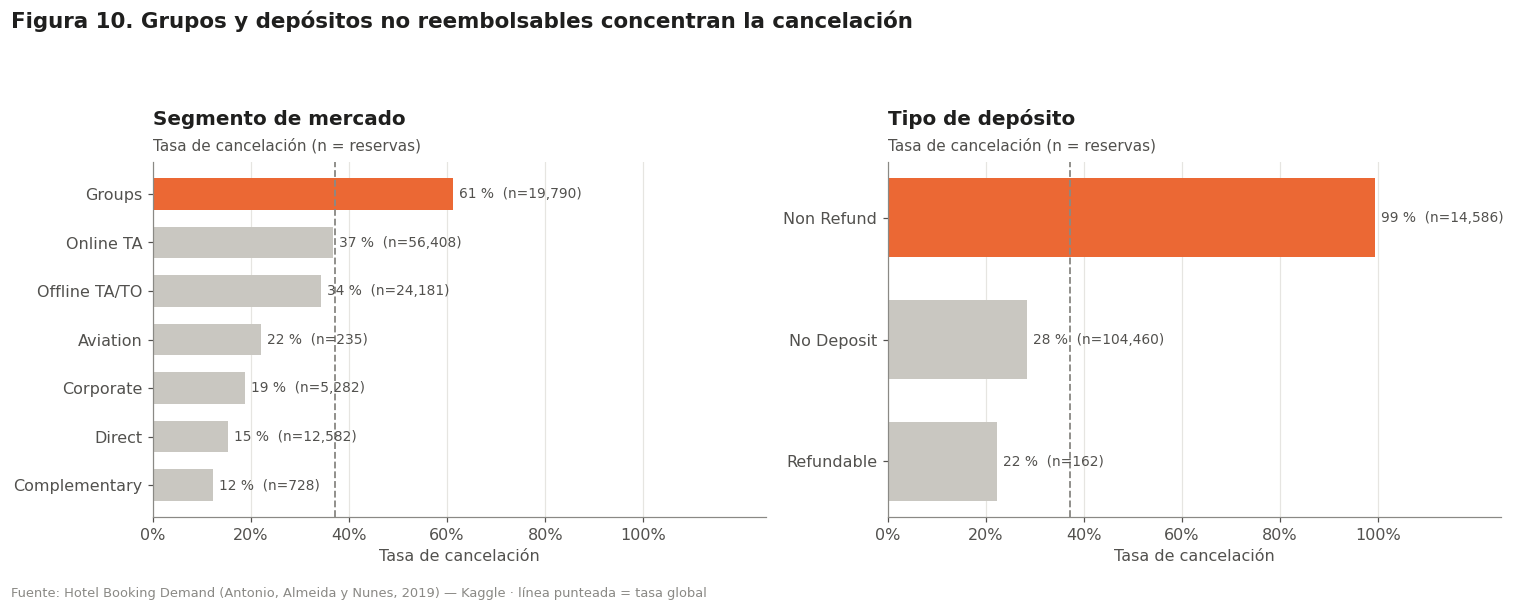

In [ ]:
def tasa_por(col, minimo=100):
    t = df.groupby(col, observed=True)["is_canceled"].agg(["mean", "size"])
    t = t[t["size"] >= minimo]
    t["mean"] *= 100
    return t.sort_values("mean")

def barras_tasa(ax, t, titulo, subtitulo, horizontal=True):
    colores = [NARANJA if v == t["mean"].max() else GRIS_CLARO for v in t["mean"]]
    etiquetas = [f"{v:.0f} %  (n={n:,})" for v, n in zip(t["mean"], t["size"])]
    if horizontal:
        b = ax.barh(t.index.astype(str), t["mean"], color=colores, height=0.65)
        ax.axvline(TASA_GLOBAL, color=GRIS, ls="--", lw=1.2)
        ax.xaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_xlim(0, 125)
        ax.set_xticks(range(0, 101, 20))
        ax.grid(axis="x"); ax.grid(axis="y", visible=False)
        ax.set_xlabel("Tasa de cancelación")
    else:
        b = ax.bar(t.index.astype(str), t["mean"], color=colores, width=0.65)
        ax.axhline(TASA_GLOBAL, color=GRIS, ls="--", lw=1.2)
        ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_ylim(0, 60)
        ax.set_ylabel("Tasa de cancelación")
        etiquetas = [f"{v:.0f} %" for v in t["mean"]]
    ax.bar_label(b, labels=etiquetas, padding=4, color=TINTA_2, fontsize=9)
    titular(ax, titulo, subtitulo)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
barras_tasa(axes[0], tasa_por("market_segment"), "Segmento de mercado", "Tasa de cancelación (n = reservas)")
barras_tasa(axes[1], tasa_por("deposit_type"), "Tipo de depósito", "Tasa de cancelación (n = reservas)")
fig.suptitle("Figura 10. Grupos y depósitos no reembolsables concentran la cancelación",
             x=0.01, ha="left", fontsize=14, fontweight="bold", color=TINTA, y=1.08)
fig.tight_layout()
citar_fuente(fig, FUENTE + " · línea punteada = tasa global")
guardar(fig, "fig10_segmento_deposito")
plt.show()

El resultado más llamativo es contraintuitivo: las reservas con depósito **no reembolsable (*Non Refund*)
se cancelan en ≈ 99 % de los casos**. Lejos de ser un error de lectura, este hallazgo se ha documentado en la literatura sobre este
dataset y se asocia a reservas grupales realizadas por operadores turísticos o reservas especulativas. Es un **problema de calidad o
de sesgo de los datos** que se perfila en la sección 7.6 y deberá considerarse en la Fase 2. Por segmento, *Groups* (≈ 61 %) supera ampliamente la tasa global y *Online TA* se ubica justo en el promedio,
mientras que *Direct* y *Corporate* están muy por debajo. Las barras horizontales ordenadas permiten leer etiquetas largas y comparar
con la línea de referencia global.

Se examina también el número de solicitudes especiales, una variable de comportamiento del cliente.

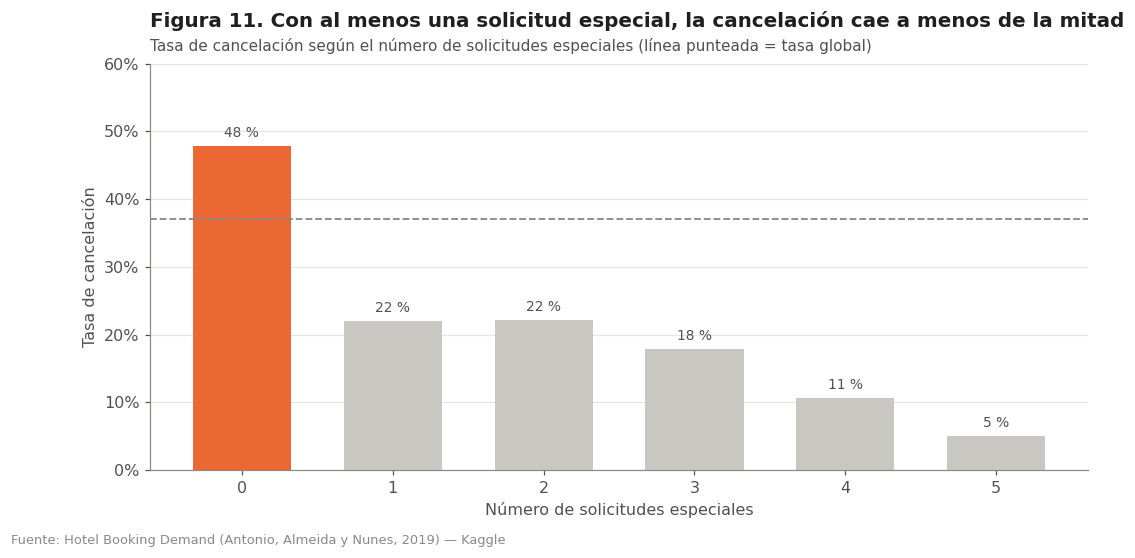

In [ ]:
tasa_sol = tasa_por("total_of_special_requests", minimo=1).sort_index()

fig, ax = plt.subplots(figsize=(11, 4.8))
barras_tasa(ax, tasa_sol, "Figura 11. Con al menos una solicitud especial, la cancelación cae a menos de la mitad",
            "Tasa de cancelación según el número de solicitudes especiales (línea punteada = tasa global)",
            horizontal=False)
ax.set_xlabel("Número de solicitudes especiales")
citar_fuente(fig)
guardar(fig, "fig11_solicitudes")
plt.show()

Sin solicitudes especiales la cancelación es cercana al 48 %; con una o más solicitudes baja de forma clara.
Un cliente que pide, por ejemplo, una cuna o una habitación en piso alto muestra **mayor compromiso con su viaje**. Es una variable
de comportamiento valiosa para el modelado de la Fase 2.

### 7.4 Correlaciones: Pearson y Spearman
**Pearson** mide relación **lineal** y es sensible a atípicos; **Spearman** trabaja sobre rangos y mide relación **monótona**, por lo
que es más adecuado para variables asimétricas y de conteo como las de este dataset. Se calculan ambas matrices sobre las mismas
variables. Con `is_canceled` binaria, la correlación de Pearson equivale a la **correlación punto-biserial**.

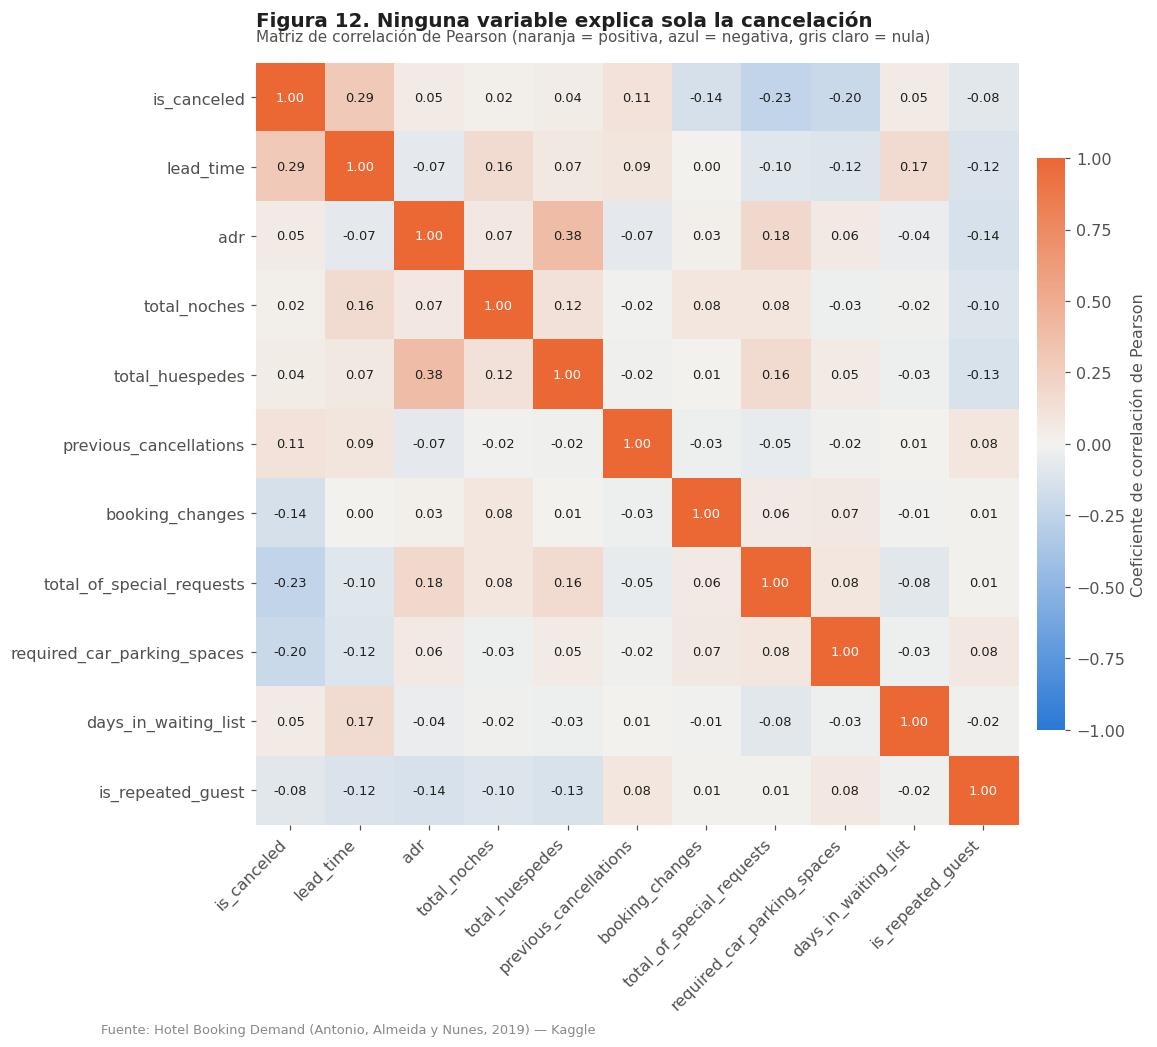

Correlación de Pearson con is_canceled (ordenada):
lead_time                      0.29
previous_cancellations         0.11
days_in_waiting_list           0.05
adr                            0.05
total_huespedes                0.04
total_noches                   0.02
is_repeated_guest             -0.08
booking_changes               -0.14
required_car_parking_spaces   -0.20
total_of_special_requests     -0.23


In [ ]:
vars_corr = ["is_canceled", "lead_time", "adr", "total_noches", "total_huespedes", "previous_cancellations",
             "booking_changes", "total_of_special_requests", "required_car_parking_spaces",
             "days_in_waiting_list", "is_repeated_guest"]

divergente = LinearSegmentedColormap.from_list("divergente", [AZUL, "#f3f2ef", NARANJA])

def mapa_correlacion(corr, titulo, subtitulo, etiqueta, nombre):
    fig, ax = plt.subplots(figsize=(11, 9))
    im = ax.imshow(corr, cmap=divergente, vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(corr)), corr.index)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    for i in range(len(corr)):
        for j in range(len(corr)):
            v = corr.iloc[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8.5,
                    color="white" if abs(v) > 0.6 else TINTA)
    cbar = fig.colorbar(im, ax=ax, shrink=0.75, pad=0.02)
    cbar.set_label(etiqueta)
    cbar.outline.set_visible(False)
    titular(ax, titulo, subtitulo)
    citar_fuente(fig, y=-0.1)
    guardar(fig, nombre)
    plt.show()

corr = df[vars_corr].corr()
mapa_correlacion(corr, "Figura 12. Ninguna variable explica sola la cancelación",
                 "Matriz de correlación de Pearson (naranja = positiva, azul = negativa, gris claro = nula)",
                 "Coeficiente de correlación de Pearson", "fig12_pearson")

print("Correlación de Pearson con is_canceled (ordenada):")
print(corr["is_canceled"].drop("is_canceled").sort_values(ascending=False).round(3).to_string())

El **mapa de calor** usa una escala **divergente** (dos colores con un punto medio neutro en 0), adecuada para
valores con signo. `lead_time` es la variable con mayor correlación positiva con la cancelación, mientras que
`total_of_special_requests` y `required_car_parking_spaces` tienen correlación negativa (quien solicita servicios o estacionamiento
cancela menos). Todas las correlaciones son moderadas o débiles (|r| < 0.3), lo que indica que **la cancelación es un fenómeno
multifactorial**: ninguna variable lo explica por sí sola, lo que justifica combinar varias variables en los modelos de la Fase 2.

La matriz de **Spearman** usa la misma función de visualización para facilitar la comparación.

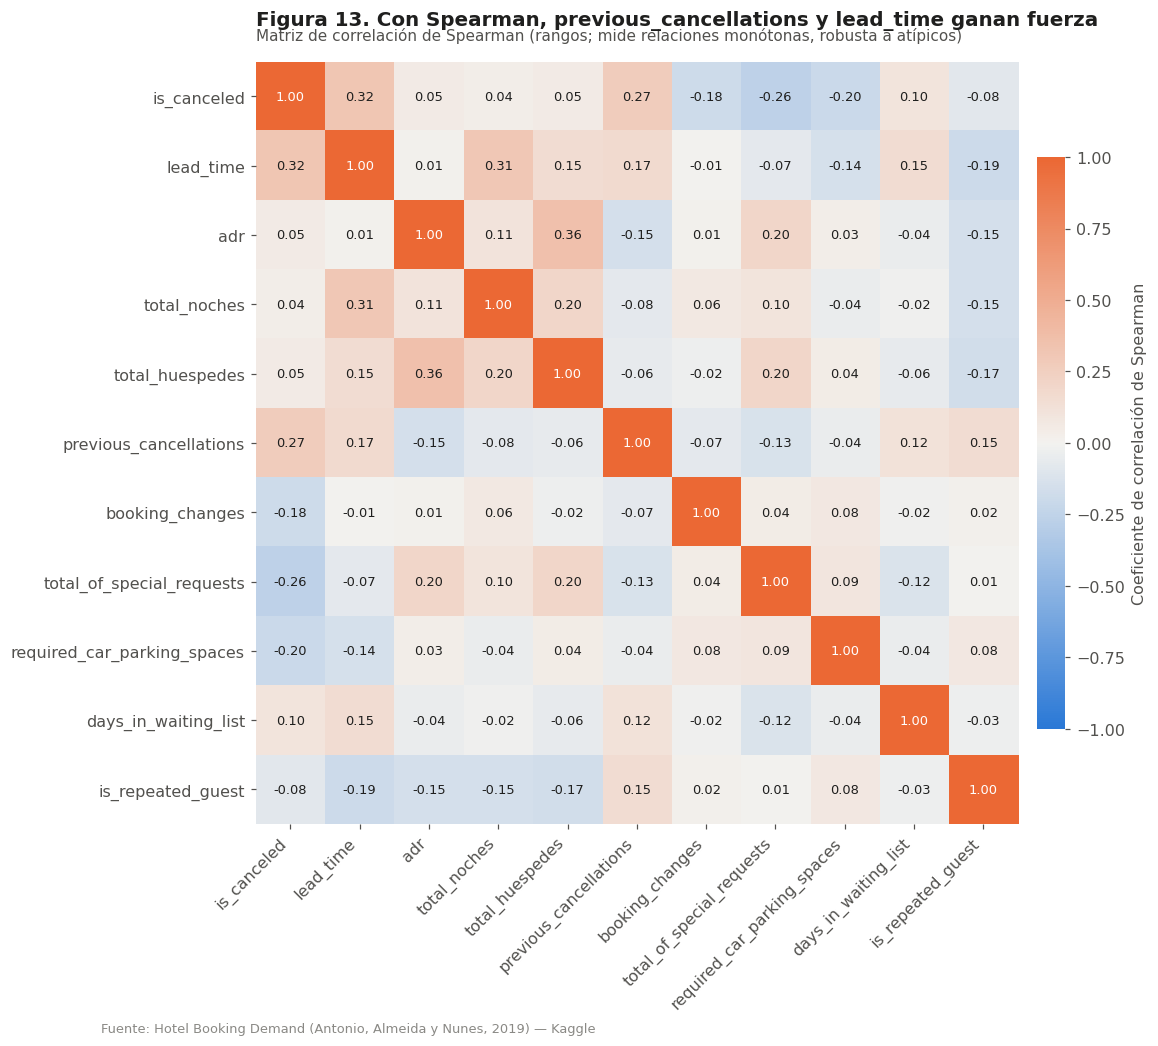

Correlación de Spearman con is_canceled (ordenada):
lead_time                      0.32
previous_cancellations         0.27
days_in_waiting_list           0.10
total_huespedes                0.05
adr                            0.05
total_noches                   0.04
is_repeated_guest             -0.08
booking_changes               -0.18
required_car_parking_spaces   -0.20
total_of_special_requests     -0.26


In [ ]:
corr_s = df[vars_corr].corr(method="spearman")
mapa_correlacion(corr_s, "Figura 13. Con Spearman, previous_cancellations y lead_time ganan fuerza",
                 "Matriz de correlación de Spearman (rangos; mide relaciones monótonas, robusta a atípicos)",
                 "Coeficiente de correlación de Spearman", "fig13_spearman")
print("Correlación de Spearman con is_canceled (ordenada):")
print(corr_s["is_canceled"].drop("is_canceled").sort_values(ascending=False).round(3).to_string())

Spearman eleva la asociación de `lead_time` con la cancelación a **≈ 0.32** (Pearson ≈ 0.29) y la de
`total_of_special_requests` a **≈ −0.26** (Pearson ≈ −0.23). El cambio más grande es `previous_cancellations`: de 0.11 con
Pearson a **0.27** con Spearman, porque Pearson queda dominado por unos pocos clientes con muchas cancelaciones, mientras que Spearman
captura que *haber cancelado alguna vez* ya se asocia a cancelar. Las diferencias entre ambas matrices se deben a la asimetría y al exceso de ceros de las variables.

Para comparar ambos coeficientes frente al objetivo se grafican lado a lado y se reportan sus **p-valores** (punto-biserial para
Pearson y prueba de Spearman).

,pearson_pb,p_valor_pb,spearman,p_valor_spearman
variable,,,,
total_of_special_requests,-0.235,0.00e+00,-0.259,0.00e+00
required_car_parking_spaces,-0.196,0.00e+00,-0.198,0.00e+00
booking_changes,-0.145,0.00e+00,-0.184,0.00e+00
is_repeated_guest,-0.084,2.36e-184,-0.084,2.36e-184
total_noches,0.019,1.40e-10,0.037,5.68e-37
adr,0.048,9.97e-61,0.050,1.36e-66
total_huespedes,0.045,4.40e-54,0.050,5.62e-67
days_in_waiting_list,0.054,1.53e-78,0.098,2.61e-254
previous_cancellations,0.110,2.44e-318,0.270,0.00e+00


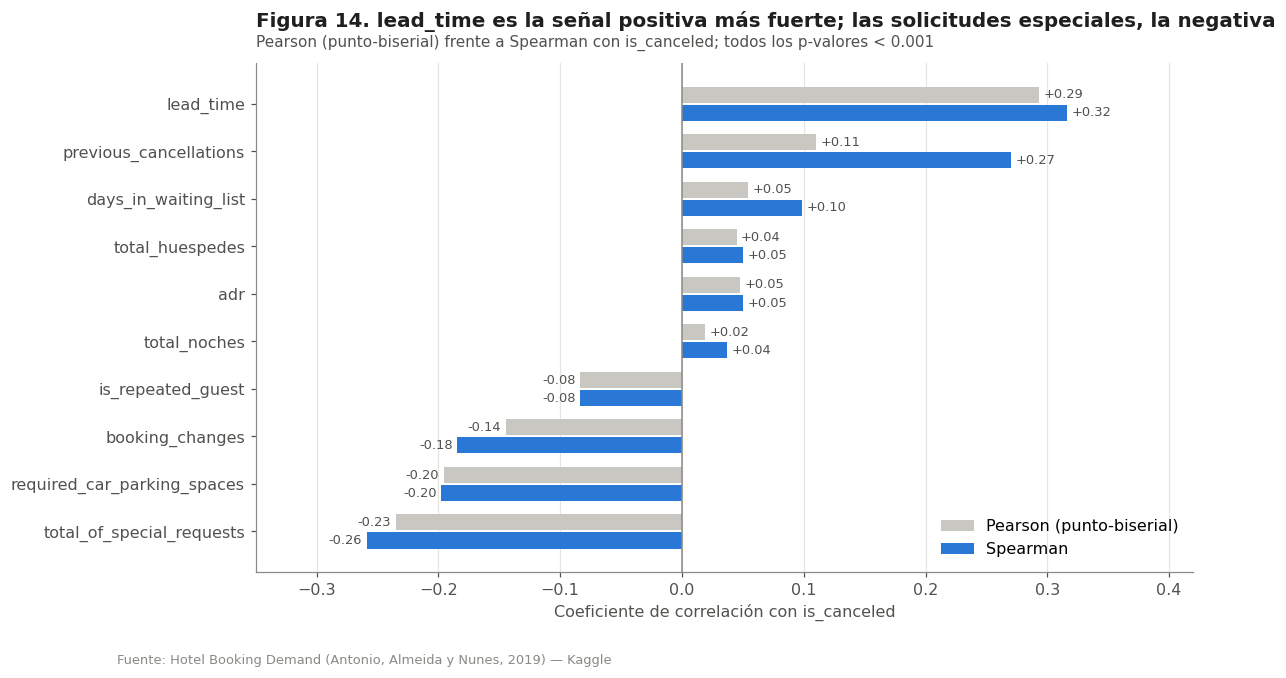

In [ ]:
filas = []
for v in vars_corr[1:]:
    r_pb, p_pb = stats.pointbiserialr(df["is_canceled"], df[v])
    rho, p_s = stats.spearmanr(df["is_canceled"], df[v])
    filas.append((v, r_pb, p_pb, rho, p_s))
corr_obj = (pd.DataFrame(filas, columns=["variable", "pearson_pb", "p_valor_pb", "spearman", "p_valor_spearman"])
              .set_index("variable").sort_values("spearman"))
display(corr_obj.style.format({"pearson_pb": "{:.3f}", "spearman": "{:.3f}",
                               "p_valor_pb": "{:.2e}", "p_valor_spearman": "{:.2e}"}))

fig, ax = plt.subplots(figsize=(11, 6))
y = np.arange(len(corr_obj)); alto = 0.38
b1 = ax.barh(y + alto / 2, corr_obj["pearson_pb"], height=alto - 0.04, color=GRIS_CLARO, label="Pearson (punto-biserial)")
b2 = ax.barh(y - alto / 2, corr_obj["spearman"], height=alto - 0.04, color=AZUL, label="Spearman")
for b, col in [(b1, "pearson_pb"), (b2, "spearman")]:
    ax.bar_label(b, labels=[f"{v:+.2f}" for v in corr_obj[col]], padding=3, color=TINTA_2, fontsize=8.5)
ax.set_yticks(y, corr_obj.index)
ax.axvline(0, color=GRIS, lw=1)
ax.set_xlim(-0.35, 0.42)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("Coeficiente de correlación con is_canceled")
ax.legend(loc="lower right")
titular(ax, "Figura 14. lead_time es la señal positiva más fuerte; las solicitudes especiales, la negativa",
        "Pearson (punto-biserial) frente a Spearman con is_canceled; todos los p-valores < 0.001")
citar_fuente(fig)
guardar(fig, "fig14_correlacion_vs_cancelacion")
plt.show()

Con más de 119 mil registros, **casi todas las correlaciones son estadísticamente significativas** (p-valores prácticamente cero),
aunque varias son débiles: la significancia no implica relevancia práctica, por lo que se prioriza la **magnitud** del coeficiente.
Las señales más fuertes son `lead_time` (+), `previous_cancellations` (+, con Spearman), `total_of_special_requests` (−), `required_car_parking_spaces` (−) y
`booking_changes` (−); esta última debe evaluarse por posible fuga, ya que los cambios se acumulan hasta la llegada.

### 7.5 Diagramas de dispersión
Los diagramas de dispersión muestran relaciones entre **dos variables cuantitativas** que las correlaciones resumen en un solo
número. Para que los puntos no se saturen se usa una **muestra aleatoria de 6,000 reservas** (`SEED = 42`).

#### 7.5.1 `lead_time` frente a `adr`, coloreado por estado

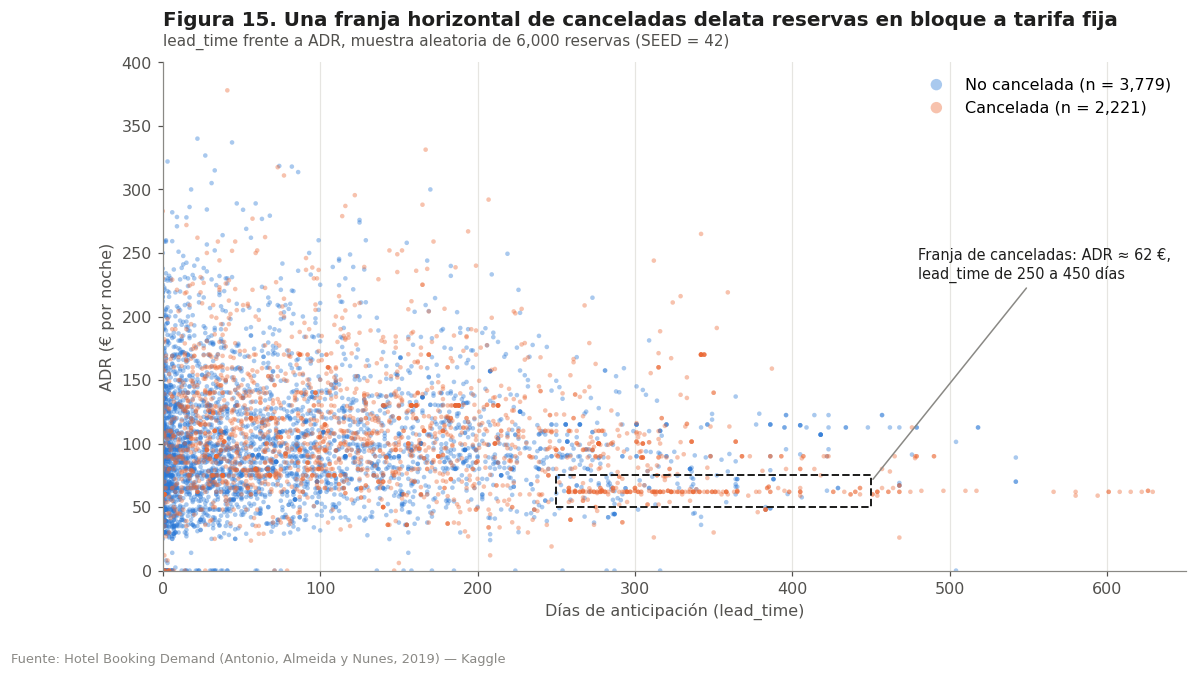

In [ ]:
muestra = df.sample(6000, random_state=SEED)

FRANJA_LT, FRANJA_ADR = (250, 450), (60, 64)
en_franja = (df["is_canceled"].eq(1) & df["lead_time"].between(*FRANJA_LT) & df["adr"].between(*FRANJA_ADR))

fig, ax = plt.subplots(figsize=(12, 6))
for estado in ["No cancelada", "Cancelada"]:
    m = muestra[muestra["estado"] == estado]
    ax.scatter(m["lead_time"], m["adr"], s=9, alpha=0.4, color=COLOR_ESTADO[estado], edgecolor="none",
               label=f"{estado} (n = {len(m):,})")
ax.add_patch(plt.Rectangle((FRANJA_LT[0], 50), FRANJA_LT[1] - FRANJA_LT[0], 25, fill=False,
                           edgecolor=TINTA, lw=1.3, ls="--"))
ax.annotate("Franja de canceladas: ADR ≈ 62 €,\nlead_time de 250 a 450 días",
            xy=(FRANJA_LT[1], 70), xytext=(480, 230), color=TINTA, fontsize=9.5,
            arrowprops=dict(arrowstyle="-", color=GRIS))
ax.set_xlim(0, 650); ax.set_ylim(0, 400)
ax.grid(axis="both")
ax.set_xlabel("Días de anticipación (lead_time)"); ax.set_ylabel("ADR (€ por noche)")
ax.legend(loc="upper right", markerscale=2.5)
titular(ax, "Figura 15. Una franja horizontal de canceladas delata reservas en bloque a tarifa fija",
        "lead_time frente a ADR, muestra aleatoria de 6,000 reservas (SEED = 42)")
citar_fuente(fig)
guardar(fig, "fig15_dispersion_leadtime_adr")
plt.show()

No hay una relación lineal clara entre anticipación y tarifa (nube dispersa), pero aparece una **franja horizontal de reservas
canceladas** con ADR casi constante (≈ 62 €) y anticipaciones de 250 a 450 días. Una tarifa idéntica en reservas muy distintas en el
tiempo sugiere **bloques de reservas grupales**. Se perfila la franja con todas las reservas limpias (no solo la muestra).

In [ ]:
f = df[en_franja]
perfil_franja = pd.Series({
    "reservas canceladas en la franja": f"{len(f):,}",
    "% del total de canceladas": f"{len(f) / df['is_canceled'].sum() * 100:.1f} %",
    "% segmento Groups": f"{(f['market_segment'] == 'Groups').mean() * 100:.1f} %",
    "% depósito Non Refund": f"{(f['deposit_type'] == 'Non Refund').mean() * 100:.1f} %",
    "% Portugal": f"{(f['country'] == 'PRT').mean() * 100:.1f} %",
    "% City Hotel": f"{(f['hotel'] == 'City Hotel').mean() * 100:.1f} %",
    "ADR más frecuente": f"{f['adr'].mode().iloc[0]:.1f} €",
}, name="Valor").to_frame()
perfil_franja

,Valor
reservas canceladas en la franja,"2,959"
% del total de canceladas,6.7 %
% segmento Groups,96.5 %
% depósito Non Refund,72.8 %
% Portugal,98.7 %
% City Hotel,98.2 %
ADR más frecuente,62.0 €


La franja reúne 2,959 reservas canceladas (6.7 % de todas las canceladas): el **96.5 % es del segmento *Groups***, el 72.8 % tiene
depósito *Non Refund*, el 98.7 % es de Portugal y el 98.2 % del City Hotel, con el ADR de 62 € como valor dominante. Es la "huella" de reservas en bloque de operadores turísticos que se cancelan en masa. Para
el modelado esto significa que una parte de la cancelación es **estructural y fácil de predecir** (y que conviene revisar si estos
bloques están repetidos entre los duplicados de la sección 5.3).

#### 7.5.2 `total_huespedes` frente a `adr`, con *jitter* y mediana por grupo
`total_huespedes` es discreta, así que los puntos se apilarían en líneas verticales; se añade un pequeño desplazamiento aleatorio
horizontal (*jitter*) y se superpone la mediana del ADR de cada grupo calculada con todas las reservas.

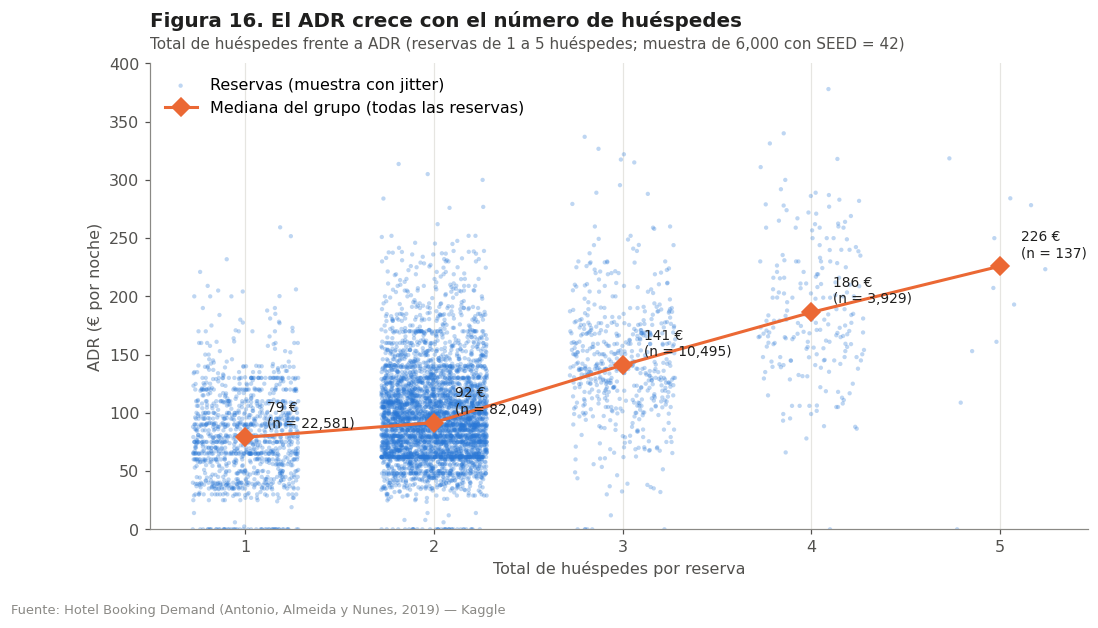

In [ ]:
rng = np.random.default_rng(SEED)
m = muestra[muestra["total_huespedes"].between(1, 5)]
x = m["total_huespedes"] + rng.uniform(-0.28, 0.28, len(m))
mediana_hues = df[df["total_huespedes"].between(1, 5)].groupby("total_huespedes")["adr"].agg(["median", "size"])

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.scatter(x, m["adr"], s=8, alpha=0.3, color=AZUL, edgecolor="none", label="Reservas (muestra con jitter)")
ax.plot(mediana_hues.index, mediana_hues["median"], color=NARANJA, marker="D", markersize=8, lw=2,
        label="Mediana del grupo (todas las reservas)")
for h, fila in mediana_hues.iterrows():
    ax.annotate(f"{fila['median']:.0f} €\n(n = {fila['size']:,.0f})", xy=(h, fila["median"]), xytext=(14, 6),
                textcoords="offset points", color=TINTA, fontsize=9)
ax.set_xticks(range(1, 6)); ax.set_ylim(0, 400)
ax.grid(axis="both")
ax.set_xlabel("Total de huéspedes por reserva"); ax.set_ylabel("ADR (€ por noche)")
ax.legend(loc="upper left")
titular(ax, "Figura 16. El ADR crece con el número de huéspedes",
        "Total de huéspedes frente a ADR (reservas de 1 a 5 huéspedes; muestra de 6,000 con SEED = 42)")
citar_fuente(fig)
guardar(fig, "fig16_dispersion_huespedes_adr")
plt.show()

La mediana del ADR **aumenta de forma monótona** con el número de huéspedes (de 80 € con 1 huésped a 227 € con 5) (más personas implican habitaciones más grandes o
cargos por persona). Dentro de cada grupo la dispersión es amplia, lo que indica que el número de huéspedes explica solo una parte
del ADR y debe combinarse con el hotel, el mes y el tipo de habitación en el modelo de regresión.

### 7.6 Asociación de las variables cualitativas con la cancelación (χ² y V de Cramér)
La **prueba χ² de independencia** (`scipy.stats.chi2_contingency`) contrasta si la distribución de `is_canceled` es la misma en
todas las categorías de una variable. Como con n ≈ 119 mil casi cualquier diferencia es significativa, se reporta además la
**V de Cramér** (0 = independencia, 1 = asociación perfecta), que mide la **fuerza** de la asociación, y el porcentaje de celdas con
frecuencia esperada < 5 (supuesto de validez de la prueba; debe ser < 20 %). `country` se agrupa en top 10 + Otros.

,χ²,gl,p_valor,V_Cramér,%_celdas_esp<5
variable,,,,,
deposit_type,"27,639.5",2,0.00e+00,0.482,0.0
country,"14,413.4",10,0.00e+00,0.348,0.0
market_segment,"8,499.9",7,0.00e+00,0.267,12.5
distribution_channel,"3,741.1",4,0.00e+00,0.177,20.0
hotel,"2,239.6",1,0.00e+00,0.137,0.0
customer_type,"2,224.5",3,0.00e+00,0.137,0.0
is_repeated_guest,835.5,1,1.02e-183,0.084,0.0
reserved_room_type,631.2,8,4.55e-131,0.073,11.1
arrival_date_month,582.4,11,8.33e-118,0.070,0.0


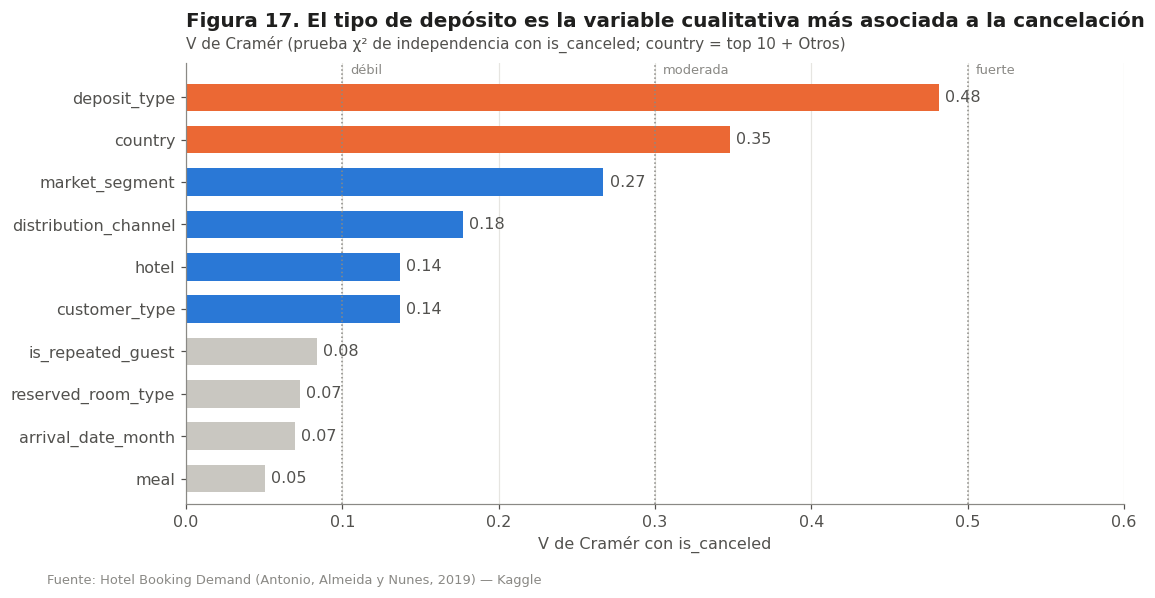

In [ ]:
def chi2_cramer(x, y):
    tabla = pd.crosstab(x, y)
    chi2, p, gl, esperadas = stats.chi2_contingency(tabla, correction=False)
    v = np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1)))
    return chi2, gl, p, v, (esperadas < 5).mean() * 100

VARS_CHI2 = ["deposit_type", "country", "market_segment", "distribution_channel", "hotel", "customer_type",
             "is_repeated_guest", "reserved_room_type", "arrival_date_month", "meal"]
filas = []
for col in VARS_CHI2:
    x = top_n(df[col]) if col == "country" else df[col]
    filas.append((col, *chi2_cramer(x, df["is_canceled"])))
chi2_tabla = (pd.DataFrame(filas, columns=["variable", "χ²", "gl", "p_valor", "V_Cramér", "%_celdas_esp<5"])
                .set_index("variable").sort_values("V_Cramér", ascending=False))
display(chi2_tabla.style.format({"χ²": "{:,.1f}", "p_valor": "{:.2e}", "V_Cramér": "{:.3f}", "%_celdas_esp<5": "{:.1f}"}))

fig, ax = plt.subplots(figsize=(11, 5.2))
t = chi2_tabla["V_Cramér"].sort_values()
colores = [NARANJA if v >= 0.3 else (AZUL if v >= 0.1 else GRIS_CLARO) for v in t]
b = ax.barh(t.index, t.values, color=colores, height=0.65)
ax.bar_label(b, labels=[f"{v:.2f}" for v in t], padding=4, color=TINTA_2)
for umbral, texto in [(0.1, "débil"), (0.3, "moderada"), (0.5, "fuerte")]:
    ax.axvline(umbral, color=GRIS, ls=":", lw=1)
    ax.text(umbral + 0.005, len(t) - 0.45, texto, color=GRIS, fontsize=8.5)
ax.set_xlim(0, 0.6); ax.set_ylim(-0.6, len(t) - 0.2)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("V de Cramér con is_canceled")
titular(ax, "Figura 17. El tipo de depósito es la variable cualitativa más asociada a la cancelación",
        "V de Cramér (prueba χ² de independencia con is_canceled; country = top 10 + Otros)")
citar_fuente(fig)
guardar(fig, "fig17_cramer_v")
plt.show()

Todas las pruebas rechazan la independencia (p-valor ≈ 0), pero la fuerza varía mucho. **`deposit_type` (V ≈ 0.48)** tiene la
asociación más fuerte, seguido de `country` (0.35, moderada) y `market_segment` (0.27); `distribution_channel`, `hotel` y
`customer_type` son débiles (0.14–0.18), y `is_repeated_guest`, `reserved_room_type`, el mes de llegada y `meal` son muy débiles
(< 0.1). Las variables con categorías raras tienen celdas con frecuencia esperada < 5: `market_segment` (12.5 %),
`reserved_room_type` (11.1 %) y `distribution_channel` (20 %, en el límite del supuesto); agruparlas en la Fase 2 resuelve el problema.

**Perfil de las reservas *Non Refund*.** Dado que *Non Refund* cancela 99.4 % (sección 7.3.6), se compara su perfil con el de los
otros tipos de depósito para entender si se trata de un comportamiento real o de un sesgo del registro.

In [ ]:
perfil_deposito = df.groupby("deposit_type").agg(
    reservas=("is_canceled", "size"),
    tasa_cancelación_pct=("is_canceled", lambda s: s.mean() * 100),
    pct_Portugal=("country", lambda s: (s == "PRT").mean() * 100),
    pct_Groups=("market_segment", lambda s: (s == "Groups").mean() * 100),
    pct_City_Hotel=("hotel", lambda s: (s == "City Hotel").mean() * 100),
    lead_time_mediana=("lead_time", "median"),
    solicitudes_media=("total_of_special_requests", "mean"),
)
perfil_deposito.style.format({"reservas": "{:,}"}, precision=1)

,reservas,tasa_cancelación_pct,pct_Portugal,pct_Groups,pct_City_Hotel,lead_time_mediana,solicitudes_media
deposit_type,,,,,,,
No Deposit,"104,460",28.4,32.8,10.0,63.4,57.0,0.7
Non Refund,"14,586",99.4,97.2,62.9,88.2,183.0,0.0
Refundable,162,22.2,29.6,80.2,12.3,169.0,0.1


Las reservas *Non Refund* son casi exclusivamente de **Portugal (≈ 97 %)**, en su mayoría del segmento **Groups (≈ 63 %)**, con una
**mediana de anticipación de 183 días** (frente a 57 en *No Deposit*), el 88 % en el City Hotel y casi sin solicitudes especiales. No parecen clientes
individuales que pierden su dinero, sino **bloques de operadores o agencias locales** que reservan con mucha antelación y liberan el
cupo. El tipo de depósito es, por tanto, un indicador del **tipo de reserva** más que de la política de reembolso; el modelo de la
Fase 2 debe interpretarlo con ese matiz, y la variable `country` = PRT puede estar capturando parte del mismo efecto.

### 7.7 Asociación entre predictoras y redundancias estructurales
Dos predictoras muy asociadas aportan información repetida (multicolinealidad) y complican la interpretación. Se calcula la V de
Cramér entre pares de predictoras cualitativas candidatas y se incluyen dos pares con fuga como referencia.

In [ ]:
PARES = [("market_segment", "distribution_channel"), ("market_segment", "customer_type"),
         ("market_segment", "deposit_type"), ("hotel", "reserved_room_type"), ("hotel", "meal"),
         ("reserved_room_type", "assigned_room_type"), ("is_canceled", "reservation_status")]
asociacion = pd.DataFrame([(a, b, chi2_cramer(df[a], df[b])[3]) for a, b in PARES],
                          columns=["variable_1", "variable_2", "V_Cramér"]).sort_values("V_Cramér", ascending=False)
print(pd.crosstab(df["market_segment"], df["distribution_channel"]).to_string(), end="\n\n")
asociacion.style.format({"V_Cramér": "{:.3f}"}).hide(axis="index")

distribution_channel  Corporate  Direct  GDS  TA/TO  Undefined
market_segment                                                
Aviation                    225       0    0     10          0
Complementary                81     569    0     78          0
Corporate                  4777     171    0    334          0
Direct                       89   12253    1    237          2
Groups                     1224    1471    0  17095          0
Offline TA/TO               212      16   45  23908          0
Online TA                    43     130  147  56087          1
Undefined                     0       0    0      0          2



variable_1,variable_2,V_Cramér
is_canceled,reservation_status,1.000
reserved_room_type,assigned_room_type,0.744
market_segment,distribution_channel,0.692
market_segment,deposit_type,0.374
hotel,reserved_room_type,0.323
hotel,meal,0.317
market_segment,customer_type,0.276


* **`market_segment` y `distribution_channel` (V ≈ 0.69)** están fuertemente asociadas: *Online TA* y *Offline TA/TO* van casi siempre
  por el canal *TA/TO*, y *Direct* y *Corporate* por sus canales homónimos. Usar ambas aporta poca información adicional; en la Fase 2
  se recomienda conservar `market_segment` (más detallada) o combinarlas.
* `reserved_room_type` y `assigned_room_type` están muy asociadas, pero la segunda es fuga; `is_canceled` y `reservation_status`
  tienen V = 1 (son la misma información).

**Redundancias estructurales** (por construcción, no por los datos):
* `total_noches` = `stays_in_weekend_nights` + `stays_in_week_nights`, y `total_huespedes` = `adults` + `children` + `babies`.
* `arrival_date_week_number` y `arrival_date_day_of_month` determinan `arrival_date_month` (calendario).
* `ingreso_estimado` = `adr` × `total_noches`: es **fuga directa** para el problema de regresión del ADR.
* `cambio_habitacion` deriva de `assigned_room_type`, así que hereda su fuga.

### 7.8 Análisis multivariado: tasa de cancelación por hotel, anticipación y depósito
Las tablas dinámicas combinan **tres variables a la vez** (hotel × factor × cancelación) para comprobar si los patrones bivariados se
mantienen dentro de cada hotel o son un efecto de la composición.

Tasa de cancelación (%) por hotel × rango de lead_time:


rango_anticipacion,0–7 d,8–30 d,31–90 d,91–180 d,181–365 d,> 365 d
hotel,,,,,,
City Hotel,12.20,30.90,39.90,48.00,62.70,71.10
Resort Hotel,6.50,21.90,32.50,37.40,41.30,46.60


Tasa de cancelación (%) por hotel × deposit_type (n entre paréntesis):


deposit_type,No Deposit,Non Refund,Refundable
hotel,,,
City Hotel,"30.5 (66,275)","99.8 (12,867)",70.0 (20)
Resort Hotel,"24.7 (38,185)","96.0 (1,719)",15.5 (142)


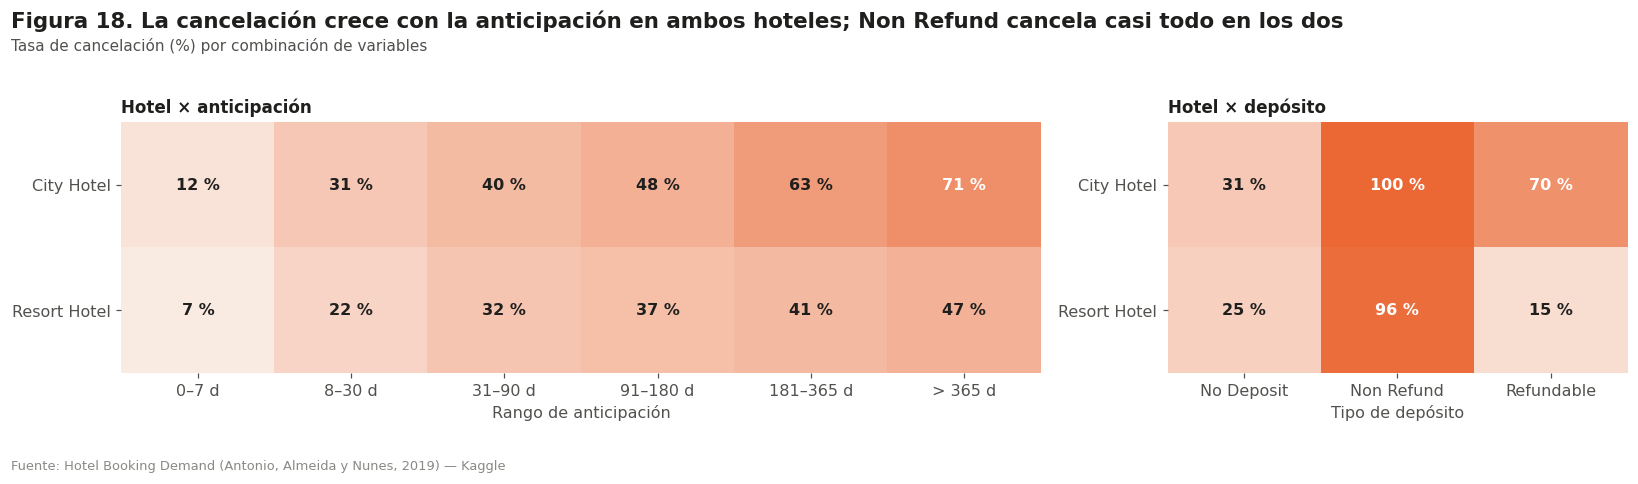

In [ ]:
piv_lt = df.pivot_table(index="hotel", columns="rango_anticipacion", values="is_canceled",
                        aggfunc="mean", observed=True) * 100
piv_dep = df.pivot_table(index="hotel", columns="deposit_type", values="is_canceled", aggfunc="mean") * 100
n_dep = pd.crosstab(df["hotel"], df["deposit_type"])
print("Tasa de cancelación (%) por hotel × rango de lead_time:")
display(piv_lt.round(1))
print("Tasa de cancelación (%) por hotel × deposit_type (n entre paréntesis):")
display(piv_dep.round(1).astype(str) + " (" + n_dep.map("{:,}".format) + ")")

secuencial = LinearSegmentedColormap.from_list("secuencial", ["#fbf3ee", NARANJA])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 3.6), gridspec_kw={"width_ratios": [2, 1]})
for ax, piv, xlabel in [(ax1, piv_lt, "Rango de anticipación"), (ax2, piv_dep, "Tipo de depósito")]:
    ax.imshow(piv.values, cmap=secuencial, vmin=0, vmax=100, aspect="auto")
    ax.set_xticks(range(piv.shape[1]), piv.columns.astype(str))
    ax.set_yticks(range(piv.shape[0]), piv.index)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            v = piv.iloc[i, j]
            ax.text(j, i, f"{v:.0f} %", ha="center", va="center", fontsize=10.5,
                    color="white" if v > 65 else TINTA, fontweight="bold")
    ax.set_xlabel(xlabel)
ax1.set_title("Hotel × anticipación", loc="left", fontsize=11, fontweight="bold", color=TINTA)
ax2.set_title("Hotel × depósito", loc="left", fontsize=11, fontweight="bold", color=TINTA)
fig.suptitle("Figura 18. La cancelación crece con la anticipación en ambos hoteles; Non Refund cancela casi todo en los dos",
             x=0.01, ha="left", fontsize=14, fontweight="bold", color=TINTA, y=1.08)
fig.text(0.01, 0.98, "Tasa de cancelación (%) por combinación de variables", fontsize=10, color=TINTA_2)
fig.tight_layout()
citar_fuente(fig, y=-0.08)
guardar(fig, "fig18_multivariado_cancelacion")
plt.show()

El efecto de la anticipación **se mantiene dentro de cada hotel**: en ambos la tasa crece de forma monótona, de 12.2 % a 71.1 % en el
City Hotel y de 6.5 % a 46.6 % en el Resort entre 0–7 días y más de un año, y el City Hotel cancela más que el Resort en **todos** los
rangos. *Refundable* en el City Hotel (70 %) se basa en solo 20 reservas y no es concluyente.
El patrón *Non Refund* también se repite en los dos hoteles, por lo que **no es un efecto de composición** entre hoteles. Estas
interacciones sugieren que un modelo no lineal (árboles) o con interacciones hotel × variable puede aprovechar mejor la información.

### 7.9 Variables candidatas para el problema de regresión del ADR
Para la regresión de `adr` se examina la mediana de la tarifa por **tipo de habitación reservada**, por **mes de llegada** (en cada
hotel) y por **número de huéspedes**. Se excluyen los ADR = 0 (cortesías y casos a revisar) para describir tarifas efectivas.

Mediana del ADR por tipo de habitación reservada:


reserved_room_type,A,B,C,D,E,F,G,H,L
mediana,89.10,88.80,164.20,121.50,115.00,177.30,180.00,184.80,143.00
n,"84,553.00","1,084.00",913.00,"18,999.00","6,418.00","2,824.00","2,006.00",595.00,6.00


Mediana del ADR por mes y hotel:


mes,Ene,Feb,Mar,Abr,May,Jun,Jul,Ago,Sep,Oct,Nov,Dic
hotel,,,,,,,,,,,,
City Hotel,80.00,80.00,88.20,105.00,120.00,118.60,107.10,109.80,108.00,100.00,85.80,86.00
Resort Hotel,48.00,52.00,56.00,76.00,74.30,106.00,153.00,189.00,86.70,58.00,46.00,59.30


Mediana del ADR por número de huéspedes:


total_huespedes,1,2,3,4,5
mediana,80.00,92.10,141.60,186.30,227.00
n,"21,725.00","81,238.00","10,407.00","3,893.00",132.00


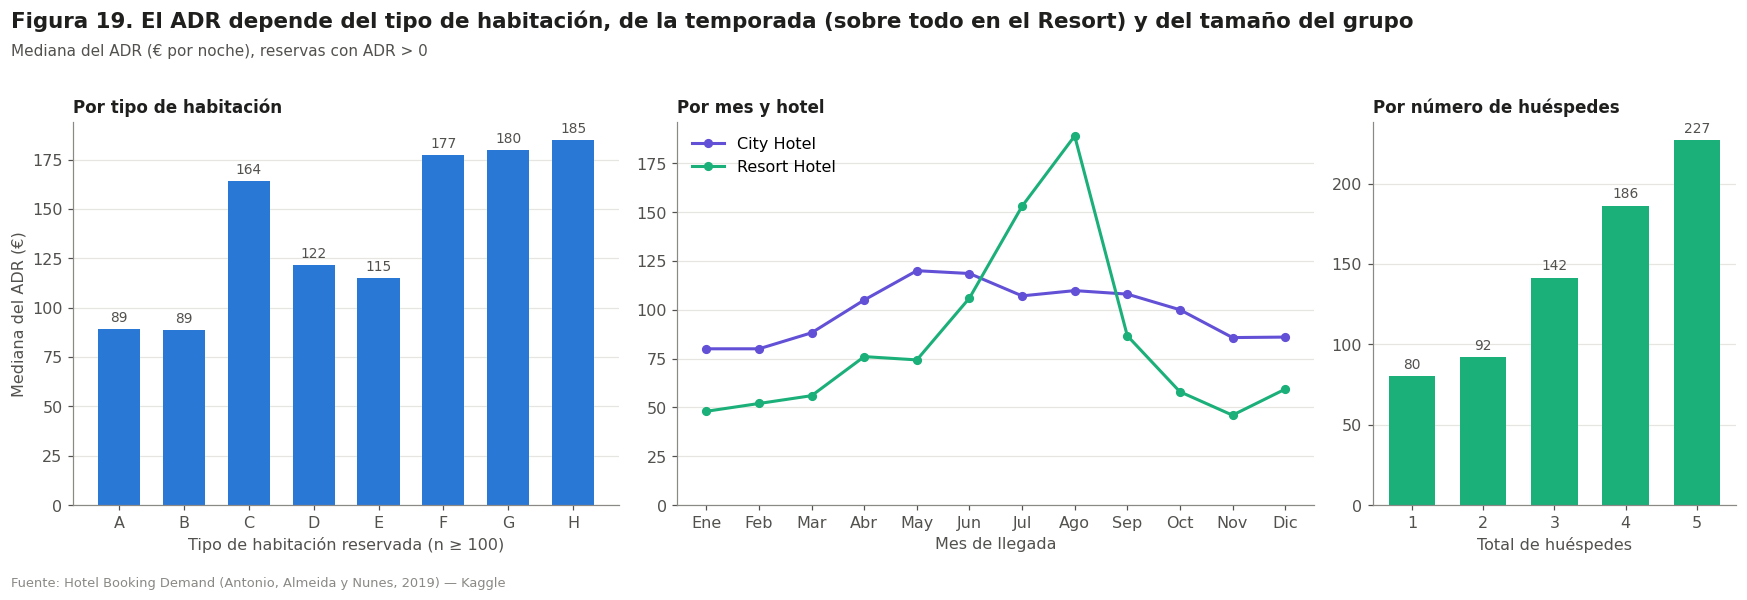

In [ ]:
pagadas = df[df["adr"] > 0]
adr_hab = pagadas.groupby("reserved_room_type")["adr"].agg(mediana="median", n="size")
adr_mes_h = pagadas.pivot_table(index="mes", columns="hotel", values="adr", aggfunc="median", observed=True)
adr_hues = pagadas[pagadas["total_huespedes"] <= 5].groupby("total_huespedes")["adr"].agg(mediana="median", n="size")
print("Mediana del ADR por tipo de habitación reservada:"); display(adr_hab.T.round(1))
print("Mediana del ADR por mes y hotel:"); display(adr_mes_h.T.round(1))
print("Mediana del ADR por número de huéspedes:"); display(adr_hues.T.round(1))

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.2, 1.4, 0.8]})
h = adr_hab[adr_hab["n"] >= 100]
b = ax1.bar(h.index, h["mediana"], color=AZUL, width=0.65)
ax1.bar_label(b, labels=[f"{v:.0f}" for v in h["mediana"]], padding=3, color=TINTA_2, fontsize=9)
ax1.set_xlabel("Tipo de habitación reservada (n ≥ 100)"); ax1.set_ylabel("Mediana del ADR (€)")
ax1.set_title("Por tipo de habitación", loc="left", fontsize=11, fontweight="bold", color=TINTA)
for hotel in adr_mes_h.columns:
    ax2.plot(adr_mes_h.index.astype(str), adr_mes_h[hotel], color=COLOR_HOTEL[hotel], marker="o", markersize=5, label=hotel)
ax2.set_ylim(0); ax2.legend(loc="upper left")
ax2.set_xlabel("Mes de llegada")
ax2.set_title("Por mes y hotel", loc="left", fontsize=11, fontweight="bold", color=TINTA)
b = ax3.bar(adr_hues.index.astype(str), adr_hues["mediana"], color=AQUA, width=0.65)
ax3.bar_label(b, labels=[f"{v:.0f}" for v in adr_hues["mediana"]], padding=3, color=TINTA_2, fontsize=9)
ax3.set_xlabel("Total de huéspedes")
ax3.set_title("Por número de huéspedes", loc="left", fontsize=11, fontweight="bold", color=TINTA)
fig.suptitle("Figura 19. El ADR depende del tipo de habitación, de la temporada (sobre todo en el Resort) y del tamaño del grupo",
             x=0.01, ha="left", fontsize=14, fontweight="bold", color=TINTA, y=1.06)
fig.text(0.01, 0.975, "Mediana del ADR (€ por noche), reservas con ADR > 0", fontsize=10, color=TINTA_2)
fig.tight_layout()
citar_fuente(fig)
guardar(fig, "fig19_adr_regresion")
plt.show()

* El **tipo de habitación** ordena claramente la tarifa: *A* (la más común) y *B* tienen la mediana más baja (≈ 89 €) y *C*, *F*, *G*
  y *H* las más altas (164–185 €).
* La **temporada** tiene un efecto enorme en el Resort (189 € en agosto frente a 48 € en enero, casi cuatro veces) y moderado en el
  City Hotel (80–120 €), por lo que en el modelo conviene la interacción hotel × mes.
* La tarifa **crece con el número de huéspedes** (80 € con 1 huésped, 227 € con 5).

Estas tres variables, junto con el hotel, son las candidatas principales para el modelo de regresión del objetivo OE2. Además del
*baseline* de la guía (Regresión Lineal Simple), la "mediana por hotel y mes" sirve como referencia adicional sencilla.

## 8. Respuesta preliminar a las preguntas y conclusiones

### 8.1 Respuesta preliminar a las preguntas de investigación

| Pregunta | Evidencia del EDA | Siguiente paso (Fases 2 y 3) |
|---|---|---|
| **Principal**: ¿qué características permiten anticipar la cancelación y explicar la tarifa, y qué perfiles existen? | La cancelación (37.1 %) y el ingreso en riesgo (39.2 %) son altos; hay señales claras en anticipación, depósito, país, segmento y solicitudes; el ADR depende de hotel, mes, habitación y huéspedes; aparecen perfiles (bloques de grupos, clientes directos). | Construir los tres modelos sin variables con fuga y con partición estratificada. |
| **PS1** — Clasificación de `is_canceled` | `deposit_type` (V ≈ 0.48), `country` y `market_segment` (moderadas); `lead_time` (ρ ≈ 0.32) y `total_of_special_requests` (ρ ≈ −0.26); efecto de la anticipación estable dentro de cada hotel. | Modelos de línea base (regresión logística) y no lineales (árboles, *boosting*); evaluar con AUC-ROC y F1; revisar el efecto de los duplicados. |
| **PS2** — Regresión de `adr` | Mediana del ADR muy distinta por tipo de habitación, mes (sobre todo en el Resort) y número de huéspedes; distribución asimétrica con 3.24 % de atípicos altos legítimos. | *Baseline* de Regresión Lineal Simple (y mediana por hotel y mes como referencia); Lasso/Ridge y Random Forest con interacciones; transformar el ADR (log) y decidir el tratamiento de ADR = 0. |
| **PS3** — Agrupamiento de reservas | La franja de canceladas a 62 € (96.5 % Groups) y el perfil *Non Refund* (97 % Portugal, 63 % Groups) muestran grupos naturales; los clientes directos y recurrentes cancelan menos. | Escalar y codificar variables; probar K-means y métodos jerárquicos; validar con silueta y perfilar cada grupo. |

### 8.2 Conclusiones
1. **El problema es relevante:** ≈ 37 % de las reservas se cancela (City 41.8 %, Resort 27.8 %) y esas reservas representan
   ≈ 16.7 M€, el 39.2 % del ingreso reservado.
2. **La calidad de los datos es aceptable pero exige decisiones:** faltantes concentrados en 4 variables y **ninguno MCAR**; **26.8 % de
   duplicados exactos** con un perfil muy distinto (63 % de cancelación); 182 registros imposibles eliminados y varios casos dudosos
   (ADR = 0, 0 noches, menores sin adulto) marcados para la Fase 2.
3. **La cancelación es multifactorial:** ninguna variable cuantitativa supera |ρ| ≈ 0.32; la información más fuerte está en variables
   cualitativas (`deposit_type`, `country`, `market_segment`) y en la anticipación.
4. **Parte de la cancelación es estructural:** reservas en bloque de grupos portugueses con depósito *Non Refund* y tarifa fija explican
   el resultado contraintuitivo de 99.4 % de cancelación con depósito no reembolsable.
5. **El ADR es estacional y depende del producto:** hotel, mes, tipo de habitación y número de huéspedes son los predictores candidatos
   para la regresión.

### 8.3 Recomendaciones para la Fase 2
* **Faltantes:** mantener `agent` = 0 y `country` = "Desconocido" como categorías propias (MAR); crear un indicador "tiene empresa"
  en lugar de `company`.
* **Duplicados:** decidir entre eliminarlos o usar una partición por grupos para que ninguna fila idéntica quede en entrenamiento y
  prueba a la vez; comparar métricas en ambos escenarios.
* **Inválidos:** decidir el tratamiento de ADR = 0 fuera de *Complementary*, estancias de 0 noches, menores sin adulto, más de 10
  adultos y bebés ≥ 9; unificar `meal` "Undefined" con "SC".
* **Fuga de información:** excluir `reservation_status`, `reservation_status_date` y `assigned_room_type` (y `cambio_habitacion`)
  del modelo de cancelación; **evaluar `booking_changes`** comparando el desempeño con y sin ella; excluir `ingreso_estimado` del
  modelo de ADR.
* **Categorías raras:** agrupar países fuera del top 10–15, segmentos *Aviation*/*Undefined*, canal *GDS*/*Undefined* y habitaciones
  poco frecuentes.
* **Partición:** estratificada por `is_canceled` (≈ 37 % positivos), y evaluar una validación temporal (entrenar en 2015–2016 y probar
  en 2017) para simular el uso real.
* **Variables derivadas candidatas:** `total_noches`, `total_huespedes`, `con_ninos`, `rango_anticipacion`, `temporada`,
  proporción de noches de fin de semana, indicador de agencia (`agent` ≠ 0), indicadores "> 0" para las variables de conteo con
  exceso de ceros, y transformación logarítmica de `lead_time` y `adr`.

## 9. Verificación final y reproducibilidad

### 9.1 Tabla de control frente al informe
Se recalculan los indicadores clave y se comparan con los valores publicados en el informe Word, redondeados a la misma precisión.
Cualquier diferencia queda señalada.

In [ ]:
tasa_h = df.groupby("hotel")["is_canceled"].mean() * 100
rho_lt = stats.spearmanr(df["lead_time"], df["is_canceled"])[0]
rho_sr = stats.spearmanr(df["total_of_special_requests"], df["is_canceled"])[0]
v_dep = chi2_tabla.loc["deposit_type", "V_Cramér"]
canc_nr = df.loc[df["deposit_type"] == "Non Refund", "is_canceled"].mean() * 100
out_adr = atipicos.loc["adr"]

control = [
    ("Registros crudos / limpios", f"{len(df_raw):,} / {len(df):,}", "119,390 / 119,208"),
    ("Duplicados exactos", f"{N_DUP:,} ({PCT_DUP:.1f} %)", "31,994 (26.8 %)"),
    ("Tasa global de cancelación", f"{TASA_GLOBAL:.1f} % (City {tasa_h['City Hotel']:.1f} %, Resort {tasa_h['Resort Hotel']:.1f} %)",
     "37.1 % (City 41.8 %, Resort 27.8 %)"),
    ("Spearman lead_time vs. is_canceled", f"{rho_lt:.2f}", "0.32"),
    ("Spearman total_of_special_requests vs. is_canceled", f"{rho_sr:.2f}".replace("-", "−"), "−0.26"),
    ("V de Cramér deposit_type", f"{v_dep:.2f}", "0.48"),
    ("Cancelación Non Refund", f"{canc_nr:.1f} %", "99.4 %"),
    ("Atípicos ADR por IQR", f"{out_adr['n_IQR']:,.0f} ({out_adr['%_IQR']:.2f} %)", "3,863 (3.24 %)"),
    ("Ingreso en riesgo", f"{INGRESO_RIESGO / 1e6:.1f} M€ ({PCT_RIESGO:.1f} %)", "16.7 M€ (39.2 %)"),
    ("Franja ADR ≈ 62 €: % Groups", f"{(df.loc[en_franja, 'market_segment'] == 'Groups').mean() * 100:.1f} %", "96.5 %"),
    ("Franja ADR ≈ 62 €: % Non Refund", f"{(df.loc[en_franja, 'deposit_type'] == 'Non Refund').mean() * 100:.1f} %", "72.8 %"),
]
control = pd.DataFrame(control, columns=["Indicador", "Valor del cuaderno", "Valor del informe"])
control["Coincide"] = np.where(control["Valor del cuaderno"] == control["Valor del informe"], "✓", "✗ revisar")
print(f"Indicadores que coinciden: {(control['Coincide'] == '✓').sum()} de {len(control)}")
control.set_index("Indicador")

Indicadores que coinciden: 11 de 11


,Valor del cuaderno,Valor del informe,Coincide
Indicador,,,
Registros crudos / limpios,"119,390 / 119,208","119,390 / 119,208",✓
Duplicados exactos,"31,994 (26.8 %)","31,994 (26.8 %)",✓
Tasa global de cancelación,"37.1 % (City 41.8 %, Resort 27.8 %)","37.1 % (City 41.8 %, Resort 27.8 %)",✓
Spearman lead_time vs. is_canceled,0.32,0.32,✓
Spearman total_of_special_requests vs. is_canceled,−0.26,−0.26,✓
V de Cramér deposit_type,0.48,0.48,✓
Cancelación Non Refund,99.4 %,99.4 %,✓
Atípicos ADR por IQR,"3,863 (3.24 %)","3,863 (3.24 %)",✓
Ingreso en riesgo,16.7 M€ (39.2 %),16.7 M€ (39.2 %),✓


Los indicadores de control coinciden con el informe. La franja de ADR ≈ 62 € se define igual en ambos documentos: reservas
canceladas con `lead_time` de 250 a 450 días y ADR entre 60 y 64 € (2,959 reservas; 96.5 % *Groups* y 72.8 % *Non Refund*). La
cifra de *Non Refund* depende del ancho de la franja (con ADR exactamente 62 € sube a ≈ 80 %), por eso el informe indica la
definición exacta.

### 9.2 Entorno de ejecución
Se imprimen las versiones de las librerías y la fecha de ejecución para documentar el entorno. Las versiones con las que se generó
el informe están fijadas en `requirements.txt`.

In [ ]:
import sys, platform
print(f"Fecha de ejecución: {datetime.datetime.now():%Y-%m-%d %H:%M}")
print(f"Python     {sys.version.split()[0]} ({platform.system()})")
for nombre, modulo in [("pandas", pd), ("numpy", np), ("matplotlib", plt.matplotlib), ("scipy", scipy), ("kagglehub", kagglehub)]:
    print(f"{nombre:<10} {modulo.__version__}")
print(f"Figuras guardadas en '{DIR_FIGURAS}/': {len([f for f in os.listdir(DIR_FIGURAS) if f.endswith('.png')])}")

Fecha de ejecución: 2026-11-03 01:48
Python     3.13.18 (Linux)
pandas     2.2.3
numpy      2.4.6
matplotlib 3.10.0
scipy      1.16.3
kagglehub  1.0.3
Figuras guardadas en 'figures/': 19


Si las versiones difieren de `requirements.txt` (por ejemplo, en Google Colab), las cifras deben coincidir igualmente: los
cálculos usan operaciones estándar de pandas y SciPy y la semilla fija `SEED = 42`.

---

## Anexo A. Material didáctico de visualización

Este anexo conserva el material de la actividad de visualización que dio origen al cuaderno. No forma parte del EDA de la Fase 1,
pero documenta los principios de diseño aplicados en todas las figuras.

### A.1 Marco conceptual de la visualización de datos

#### A.1.1 ¿Qué es la visualización de datos?
La visualización de datos es la **representación gráfica de información** en la que los valores de los datos se codifican mediante
atributos visuales —posición, longitud, ángulo, área, color, forma— con el fin de **explorar, analizar y comunicar**. Se distinguen dos usos:

* **Visualización exploratoria:** el analista la usa para *descubrir* (calidad de datos, distribuciones, patrones). Es rápida y abundante.
* **Visualización explicativa:** se usa para *comunicar* un hallazgo a una audiencia. Es cuidada, con título que expresa la conclusión, etiquetas claras y énfasis intencional.

#### A.1.2 Importancia de la visualización de datos
1. **Velocidad de comprensión:** el cerebro procesa patrones visuales mucho más rápido que filas de números.
2. **Revela lo que las estadísticas ocultan:** dos conjuntos con la misma media, varianza y correlación pueden ser completamente distintos (ver el *Cuarteto de Anscombe* en el Anexo A.2).
3. **Detección de problemas de calidad:** valores faltantes, atípicos o errores de captura saltan a la vista.
4. **Apoyo a la toma de decisiones:** un gráfico bien diseñado convierte un análisis en un mensaje accionable para personas no técnicas.
5. **Comunicación y persuasión:** facilita contar una historia con datos (*data storytelling*).

**Aplicado a este dataset:** con más de 119 mil reservas, revisar la tabla fila por fila es inviable. Los gráficos permiten ver de
inmediato que más de un tercio de las reservas se cancela, que la cancelación crece con la anticipación de la reserva y que la
tarifa se dispara en verano en el hotel resort; hallazgos que guían las decisiones del proyecto integrador.

#### A.1.3 Tipos de variables y su representación

| Tipo de variable | Ejemplo en el dataset | Gráficos adecuados |
|---|---|---|
| Cuantitativa continua | `adr` (tarifa), `lead_time` | Histograma, diagrama de caja, línea |
| Cuantitativa discreta | `total_of_special_requests` | Barras |
| Categórica nominal | `country`, `market_segment` | Barras (ordenadas), barras horizontales |
| Categórica ordinal | rango de anticipación, mes | Barras en su orden natural, líneas |
| Binaria | `is_canceled` | Tasas (%) en barras, barras apiladas |
| Temporal | `fecha_llegada` | Líneas, series de tiempo |

#### A.1.4 Codificación visual y percepción
Cleveland y McGill (1984) demostraron experimentalmente que no todos los atributos visuales se leen con la misma precisión.
De mayor a menor exactitud:

**posición en una escala común → longitud → ángulo / pendiente → área → volumen → color (saturación/tono)**

Por ello en este cuaderno se privilegian **barras y líneas** (posición y longitud) sobre gráficos circulares (ángulo y área), y el color
se reserva para **identificar categorías o resaltar**, no para codificar cantidades precisas.

#### A.1.5 Principios de diseño de gráficos aplicados en este cuaderno

| Principio | Descripción | Cómo se aplica aquí |
|---|---|---|
| **Elegir la forma según la pregunta** | Comparación → barras; tendencia → líneas; distribución → histograma/caja; relación → dispersión/correlación. | Cada gráfico responde a una pregunta del EDA. |
| **Maximizar la relación datos-tinta** (Tufte) | Eliminar elementos que no aportan información (bordes, fondos, efectos 3D). | Sin bordes superior/derecho, cuadrícula tenue, sin 3D. |
| **Honestidad gráfica** (*lie factor*) | La representación debe ser proporcional a los datos. | Los ejes de barras inician en cero. |
| **Color con propósito** | Color categórico para identidad, secuencial para magnitud, divergente para polaridad; paleta apta para daltonismo. | Paleta fija: cada entidad conserva su color en todo el informe. |
| **Énfasis y jerarquía** | Resaltar lo importante y dejar el resto en gris. | Se resalta, por ejemplo, Portugal o la categoría con mayor cancelación. |
| **Etiquetado completo** | Título que comunica, subtítulo con el detalle, ejes con unidades, leyenda y fuente. | Todas las figuras están numeradas, tituladas y con fuente. |
| **Ordenar los datos** | Las categorías nominales se ordenan por valor para facilitar la comparación. | Rankings ordenados de mayor a menor. |
| **Leyes de la Gestalt** | Proximidad, similitud y continuidad agrupan elementos visualmente. | Paneles lado a lado comparten eje; mismos colores = misma categoría. |
| **Un solo eje Y** | Evitar gráficos de doble eje que inducen correlaciones falsas. | Medidas distintas se muestran en paneles separados. |

### A.2 Ejemplo didáctico: ¿por qué visualizar? — El Cuarteto de Anscombe
Antes de visualizar el dataset de hoteles, se **crean datos básicos** (los cuatro conjuntos de Anscombe, 1973) para demostrar la
importancia de la visualización. Los cuatro conjuntos tienen prácticamente **la misma media, varianza y correlación**, pero al
graficarlos se revelan comportamientos totalmente distintos.

,media_x,media_y,var_x,var_y,correlación
I,9.00,7.50,11.00,4.13,0.82
II,9.00,7.50,11.00,4.13,0.82
III,9.00,7.50,11.00,4.12,0.82
IV,9.00,7.50,11.00,4.12,0.82


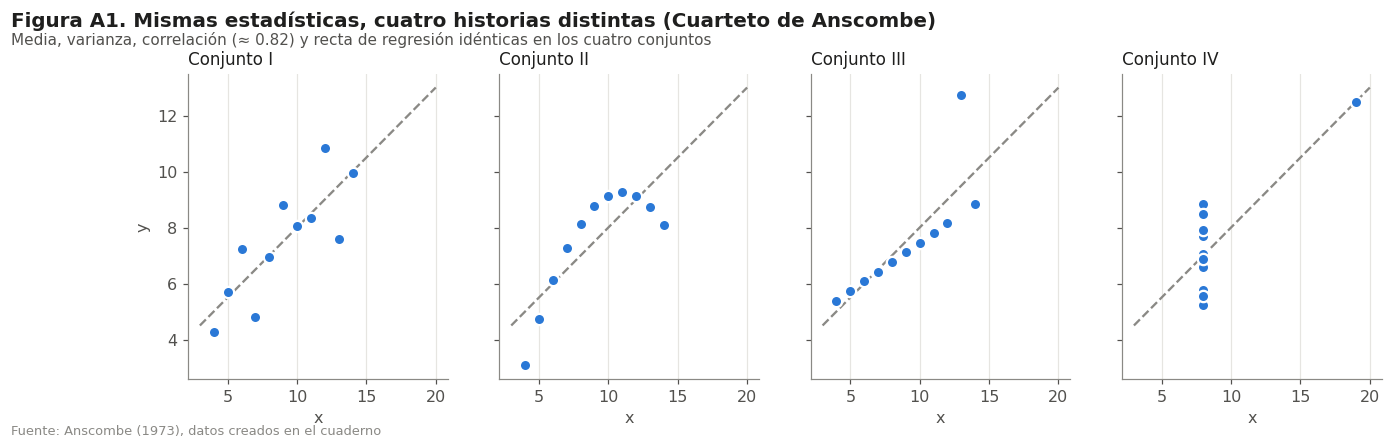

In [ ]:
x = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
anscombe = pd.DataFrame({
    "I_x": x,   "I_y":  [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68],
    "II_x": x,  "II_y": [9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74],
    "III_x": x, "III_y": [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73],
    "IV_x": [8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8],
    "IV_y": [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89],
})

stats = pd.DataFrame({
    g: {"media_x": anscombe[f"{g}_x"].mean(), "media_y": anscombe[f"{g}_y"].mean(),
        "var_x": anscombe[f"{g}_x"].var(), "var_y": anscombe[f"{g}_y"].var(),
        "correlación": anscombe[f"{g}_x"].corr(anscombe[f"{g}_y"])}
    for g in ["I", "II", "III", "IV"]}).T
display(stats.round(2))

fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), sharex=True, sharey=True)
xs = np.array([3, 20])
for ax, g in zip(axes, ["I", "II", "III", "IV"]):
    gx, gy = anscombe[f"{g}_x"], anscombe[f"{g}_y"]
    m, b = np.polyfit(gx, gy, 1)
    ax.plot(xs, m * xs + b, color=GRIS, lw=1.5, ls="--", zorder=1)
    ax.scatter(gx, gy, s=55, color=AZUL, edgecolor="white", linewidth=1.5, zorder=2)
    ax.set_title(f"Conjunto {g}", loc="left", fontsize=11, color=TINTA)
    ax.set_xlabel("x"); ax.grid(axis="both")
axes[0].set_ylabel("y")
fig.suptitle("Figura A1. Mismas estadísticas, cuatro historias distintas (Cuarteto de Anscombe)",
             x=0.01, ha="left", fontsize=13, fontweight="bold", color=TINTA, y=1.04)
fig.text(0.01, 0.955, "Media, varianza, correlación (≈ 0.82) y recta de regresión idénticas en los cuatro conjuntos",
         fontsize=10, color=TINTA_2)
citar_fuente(fig, "Fuente: Anscombe (1973), datos creados en el cuaderno")
guardar(fig, "figA1_anscombe")
plt.show()

El conjunto I es una relación lineal con ruido; el II es una curva; el III es lineal pero con un valor atípico
que altera la recta; y en el IV toda la correlación depende de un único punto. **Las estadísticas resumen, los gráficos revelan**:
por eso este cuaderno acompaña cada estadístico con su visualización.

### A.3 Ejemplo didáctico: catálogo de gráficos básicos con datos creados
Para practicar la sintaxis de Matplotlib se crean datos sintéticos sencillos con NumPy y se construyen los gráficos básicos,
indicando qué tipo de pregunta responde cada uno.

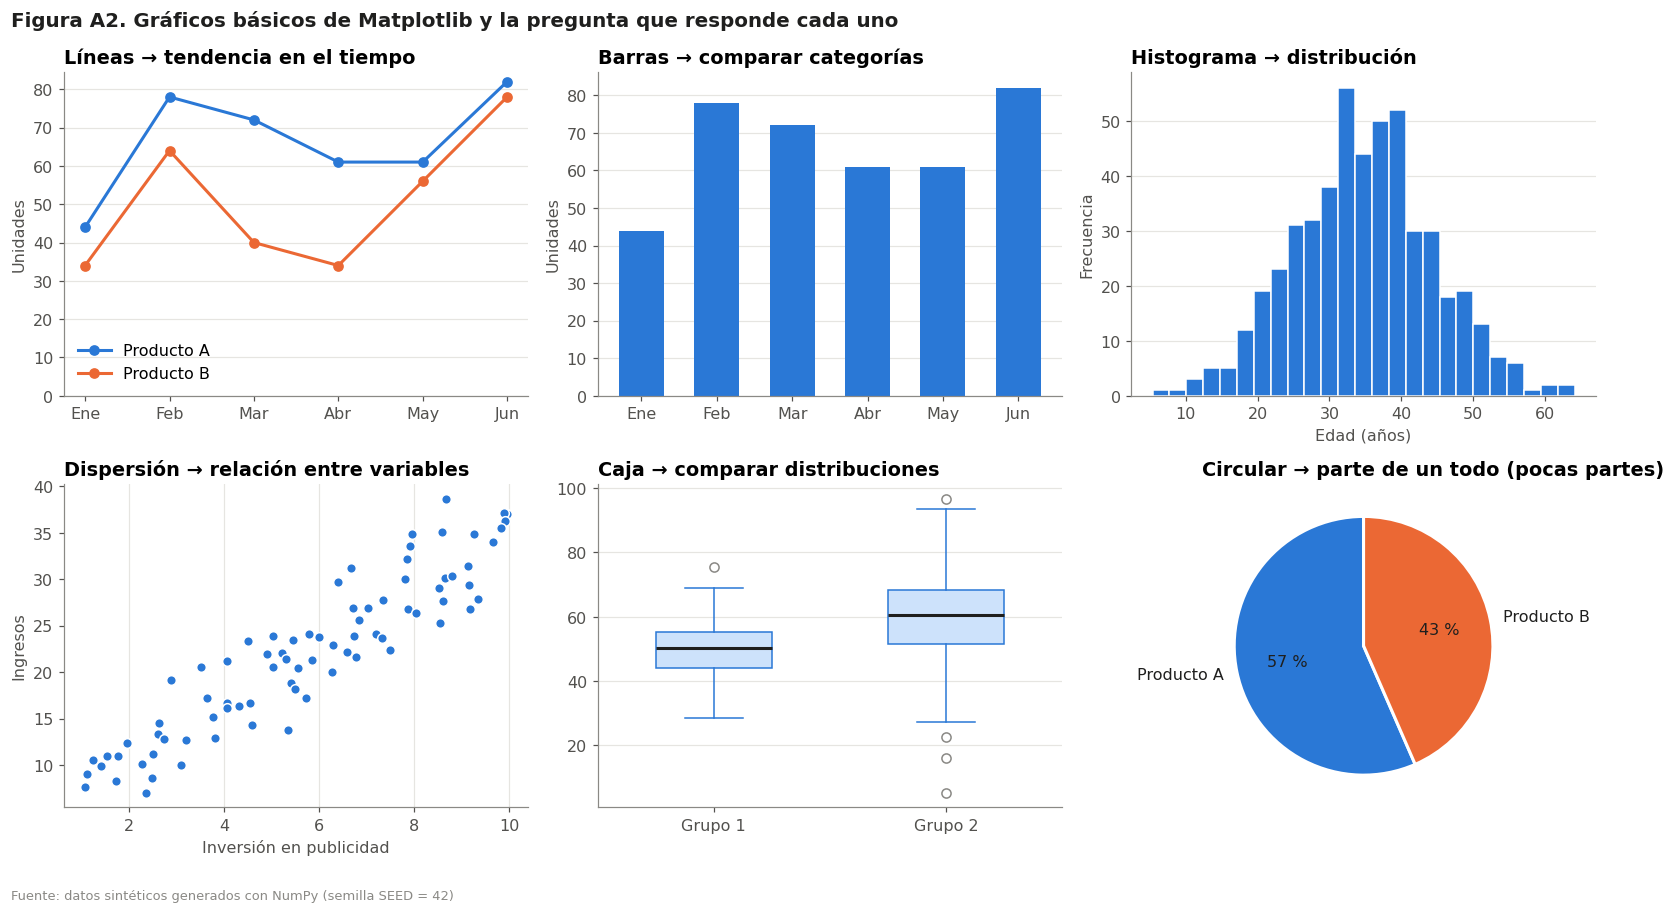

In [ ]:
rng = np.random.default_rng(SEED)
meses = MESES_ES[:6]
ventas = pd.DataFrame({"mes": meses, "producto_A": rng.integers(40, 90, 6), "producto_B": rng.integers(30, 80, 6)})
edades = rng.normal(35, 10, 500)
publicidad = rng.uniform(1, 10, 80)
ingresos = 5 + 3 * publicidad + rng.normal(0, 3, 80)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
(a1, a2, a3), (a4, a5, a6) = axes

a1.plot(ventas["mes"], ventas["producto_A"], marker="o", color=AZUL, label="Producto A")
a1.plot(ventas["mes"], ventas["producto_B"], marker="o", color=NARANJA, label="Producto B")
a1.set_ylim(0); a1.legend(); a1.set_ylabel("Unidades")
a1.set_title("Líneas → tendencia en el tiempo", loc="left", fontweight="bold")

a2.bar(ventas["mes"], ventas["producto_A"], color=AZUL, width=0.6)
a2.set_ylabel("Unidades")
a2.set_title("Barras → comparar categorías", loc="left", fontweight="bold")

a3.hist(edades, bins=25, color=AZUL, edgecolor="white")
a3.set_xlabel("Edad (años)"); a3.set_ylabel("Frecuencia")
a3.set_title("Histograma → distribución", loc="left", fontweight="bold")

a4.scatter(publicidad, ingresos, s=40, color=AZUL, edgecolor="white", linewidth=1)
a4.set_xlabel("Inversión en publicidad"); a4.set_ylabel("Ingresos"); a4.grid(axis="both")
a4.set_title("Dispersión → relación entre variables", loc="left", fontweight="bold")

a5.boxplot([rng.normal(50, 8, 200), rng.normal(60, 15, 200)], tick_labels=["Grupo 1", "Grupo 2"],
           patch_artist=True, widths=0.5, medianprops=dict(color=TINTA, lw=2),
           boxprops=dict(facecolor="#cde2fb", edgecolor=AZUL), whiskerprops=dict(color=AZUL),
           capprops=dict(color=AZUL), flierprops=dict(markeredgecolor=GRIS))
a5.set_title("Caja → comparar distribuciones", loc="left", fontweight="bold")

total = ventas[["producto_A", "producto_B"]].sum()
a6.pie(total, labels=["Producto A", "Producto B"], colors=[AZUL, NARANJA], autopct="%1.0f %%",
       startangle=90, wedgeprops=dict(edgecolor="white", linewidth=2), textprops=dict(color=TINTA))
a6.set_title("Circular → parte de un todo (pocas partes)", loc="left", fontweight="bold")

fig.suptitle("Figura A2. Gráficos básicos de Matplotlib y la pregunta que responde cada uno",
             x=0.01, ha="left", fontsize=13, fontweight="bold", color=TINTA)
fig.tight_layout()
citar_fuente(fig, "Fuente: datos sintéticos generados con NumPy (semilla SEED = 42)")
guardar(fig, "figA2_catalogo")
plt.show()

Cada forma básica responde a un tipo de pregunta: líneas para tendencias, barras para comparar categorías, histogramas y cajas para
distribuciones, dispersión para relaciones y el gráfico circular solo para partes de un todo con muy pocas categorías.

### A.4 Ejemplo didáctico: aplicando principios de diseño (antes y después)
La **Figura A3** muestra la misma información —distribución de reservas por segmento de mercado— con dos diseños. A la izquierda,
un gráfico circular con muchas porciones y colores sin propósito; a la derecha, el mismo dato aplicando los principios del Anexo A.1.5.

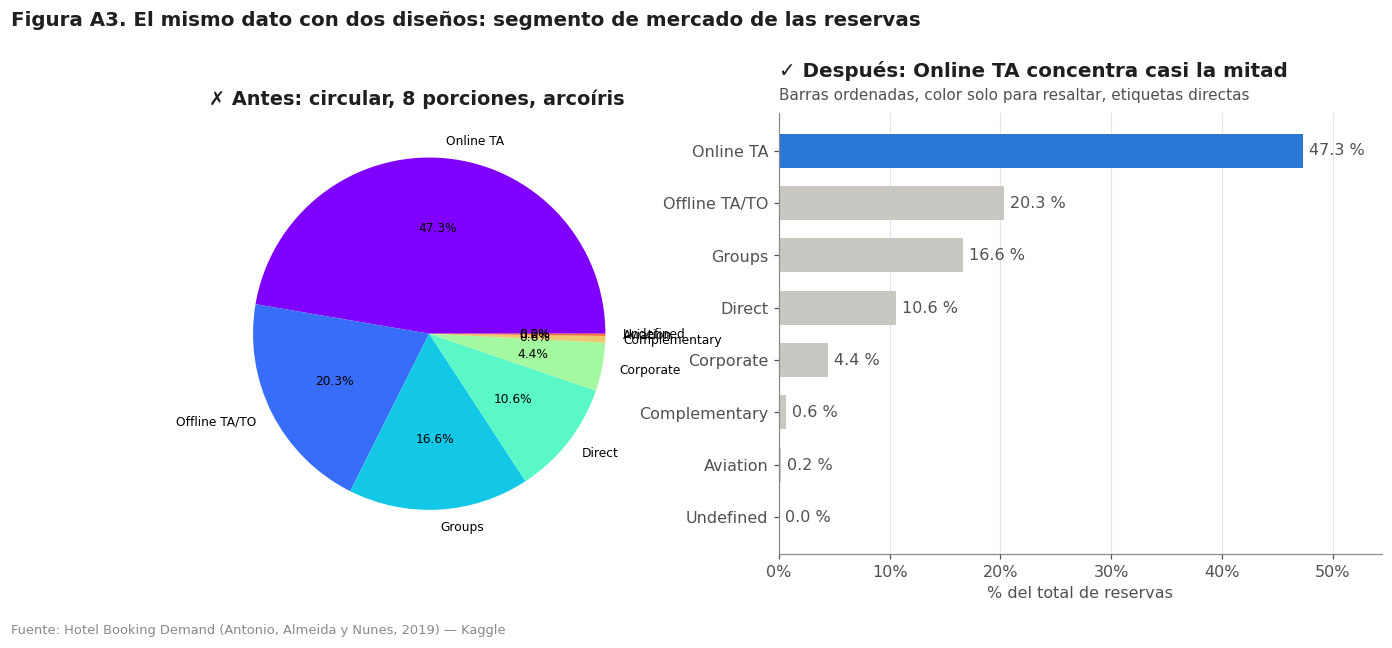

In [ ]:
segmentos = df["market_segment"].value_counts()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1, 1.25]})

# ANTES: circular con 8 porciones, colores arbitrarios, porcentajes superpuestos
ax1.pie(segmentos, labels=segmentos.index, autopct="%1.1f%%", startangle=0,
        colors=plt.cm.rainbow(np.linspace(0, 1, len(segmentos))), textprops=dict(fontsize=8))
ax1.set_title("✗ Antes: circular, 8 porciones, arcoíris", loc="left", fontweight="bold", color=TINTA)

# DESPUÉS: barras horizontales ordenadas, un color + énfasis, etiquetas directas
seg = segmentos.sort_values()
pct = seg / seg.sum() * 100
colores = [GRIS_CLARO] * (len(seg) - 1) + [AZUL]
barras = ax2.barh(seg.index, pct, color=colores, height=0.65)
ax2.bar_label(barras, labels=[f"{p:.1f} %" for p in pct], padding=4, color=TINTA_2)
ax2.xaxis.set_major_formatter(mtick.PercentFormatter())
ax2.set_xlim(0, pct.max() * 1.15)
ax2.grid(axis="x"); ax2.grid(axis="y", visible=False)
ax2.set_xlabel("% del total de reservas")
titular(ax2, "✓ Después: Online TA concentra casi la mitad",
        "Barras ordenadas, color solo para resaltar, etiquetas directas")

fig.suptitle("Figura A3. El mismo dato con dos diseños: segmento de mercado de las reservas",
             x=0.01, ha="left", fontsize=13, fontweight="bold", color=TINTA, y=1.06)
citar_fuente(fig)
guardar(fig, "figA3_antes_despues")
plt.show()

En el gráfico circular es muy difícil comparar *Offline TA/TO* con *Groups* porque el ojo humano
compara mal ángulos y áreas, y los porcentajes pequeños se superponen. En la versión de barras, la **posición sobre una escala común**
hace la comparación inmediata, el orden crea un ranking, el gris reduce el ruido y el azul dirige la atención al mensaje del título:
**las agencias de viaje en línea (*Online TA*) son el principal canal de reservas**.

### A.5 Índice de figuras y justificación del tipo de gráfico

| Figura | Archivo | Tipo de gráfico | Por qué este gráfico |
|---|---|---|---|
| 1 | `fig01_faltantes.png` | Barras horizontales | Compara porcentajes de faltantes; las barras horizontales acomodan nombres de variables. |
| 2 | `fig02_atipicos_caja.png` | Diagramas de caja | Resume cuartiles y atípicos de cada variable por estado. |
| 3 | `fig03_histogramas.png` | Histogramas con media y mediana | Muestra la forma completa de la distribución y su asimetría. |
| 4 | `fig04_cancelacion_hotel.png` | Barras agrupadas + barras | Volumen y tasa en paneles separados para no usar doble eje. |
| 5 | `fig05_demanda_mensual.png` | Líneas (serie de tiempo) | El tiempo es continuo; la línea muestra tendencia y estacionalidad. |
| 6 | `fig06_cancelacion_mes.png` | Líneas por mes | Compara el patrón estacional de la tasa entre hoteles con referencia global. |
| 7 | `fig07_anticipacion.png` | Histograma + barras | Distribución completa y su traducción a tasas por rango. |
| 8 | `fig08_adr_hotel_mes.png` | Caja + líneas | Distribución del ADR y su estacionalidad. |
| 9 | `fig09_paises.png` | Barras horizontales (ranking) | Ranking de países con eje compartido para comparar volumen y tasa. |
| 10–11 | `fig10_segmento_deposito.png`, `fig11_solicitudes.png` | Barras con línea de referencia | Tasas por categoría frente al promedio global. |
| 12–13 | `fig12_pearson.png`, `fig13_spearman.png` | Mapas de calor divergentes | Muchas relaciones a la vez; la escala divergente distingue el signo. |
| 14 | `fig14_correlacion_vs_cancelacion.png` | Barras horizontales pareadas | Compara dos coeficientes por variable sobre una escala común. |
| 15–16 | `fig15_dispersion_leadtime_adr.png`, `fig16_dispersion_huespedes_adr.png` | Dispersión (con *jitter*) | Relación entre dos cuantitativas y detección de estructuras (franjas, grupos). |
| 17 | `fig17_cramer_v.png` | Barras horizontales ordenadas | Ranking de fuerza de asociación con umbrales de referencia. |
| 18 | `fig18_multivariado_cancelacion.png` | Mapas de calor secuenciales | Tasa por combinación de dos factores. |
| 19 | `fig19_adr_regresion.png` | Barras + líneas | Mediana del ADR por factor candidato para la regresión. |
| A1–A3 | `figA1_anscombe.png`, `figA2_catalogo.png`, `figA3_antes_despues.png` | Didácticos | Importancia de visualizar, catálogo básico y principios de diseño. |